# **Clasificación de la forma reportada en avistamientos de OVNIS en Estados Unidos mediante aprendizaje automático**

**Alumno:** Ariel Tuñon  
**Institución:** Politécnico Superior Malvinas Argentinas   
**Año:** 2026

---
# Limpieza y pre-procesamiento

**Dataset:** NUFORC UFO Sightings - Data scraped from the National UFO reporting center – By Thaddeus Segura - (DbCL) v1.0


#CARGA DEL DATASET


In [1]:
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.filterwarnings('ignore')
import cufflinks as cf
import plotly.offline
cf.go_offline()
cf.set_config_file(offline=False, world_readable=True)
import kagglehub

print("Descargando la última versión del dataset desde Kaggle...")

# Descargar el dataset usando kagglehub
path = kagglehub.dataset_download("thaddeussegura/ufo-sightings")
print("Ruta de los archivos descargados:", path)

# Listar los archivos disponibles en el directorio descargado para identificar el CSV exacto
files = os.listdir(path)
print(f"Archivos encontrados: {files}")

# Buscar el archivo CSV en el directorio descargado
csv_file = [f for f in files if f.endswith('.csv')][0]
csv_path = os.path.join(path, csv_file)

print(f"\nCargando el archivo '{csv_file}' en memoria...")

# Cargar el dataset en un DataFrame de pandas
df = pd.read_csv(csv_path, low_memory=False, on_bad_lines='skip')

print(f"\n¡Dataset cargado exitosamente!")
print(f"Total de registros (filas): {df.shape[0]:,}")
print(f"Total de columnas: {df.shape[1]}")

print("\n--- Primeras filas del dataset (.head()) ---")
display(df.head())

Descargando la última versión del dataset desde Kaggle...
Using Colab cache for faster access to the 'ufo-sightings' dataset.
Ruta de los archivos descargados: /kaggle/input/ufo-sightings
Archivos encontrados: ['clean_ufo_data.csv']

Cargando el archivo 'clean_ufo_data.csv' en memoria...

¡Dataset cargado exitosamente!
Total de registros (filas): 120,785
Total de columnas: 9

--- Primeras filas del dataset (.head()) ---


,id,occurred_date_time,city,state,shape,duration,summary,details_url,posted_date
0,147518,7/12/19 09:20,Redding,CA,Cylinder,5 minutes,"North Redding, CA. We saw a bright flashing w...",http://www.nuforc.org/webreports/147/S147518.html,7/12/19
1,147514,7/12/19 03:30,Charlotte,NC,Other,20 minutes,Whooshing sound with 1-red and 3-white lights ...,http://www.nuforc.org/webreports/147/S147514.html,7/12/19
2,147511,7/11/19 22:40,Cedar Creek,TX,Other,20 seconds,"Sitting on my front porch a few minutes ago, w...",http://www.nuforc.org/webreports/147/S147511.html,7/12/19
3,147512,7/11/19 22:10,San Bernardino,CA,Triangle,2 minutes,On the freeway on my way home from a distance....,http://www.nuforc.org/webreports/147/S147512.html,7/12/19
4,147509,7/11/19 22:00,Bowling Green,KY,Other,45 minutes,Me and my girlfriend watched as we first seen ...,http://www.nuforc.org/webreports/147/S147509.html,7/12/19


# VISUALIZACIÓN DE LOS DATOS

In [2]:

# Nombres de las columnas
print("\nColumnas:")
print(df.columns.tolist())

# Información general
print("\nInformación del dataset:")
df.info()


Columnas:
['id', 'occurred_date_time', 'city', 'state', 'shape', 'duration', 'summary', 'details_url', 'posted_date']

Información del dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120785 entries, 0 to 120784
Data columns (total 9 columns):
 #   Column              Non-Null Count   Dtype 
---  ------              --------------   ----- 
 0   id                  120785 non-null  int64 
 1   occurred_date_time  120724 non-null  object
 2   city                120524 non-null  object
 3   state               112071 non-null  object
 4   shape               116687 non-null  object
 5   duration            116413 non-null  object
 6   summary             120748 non-null  object
 7   details_url         120785 non-null  object
 8   posted_date         120785 non-null  object
dtypes: int64(1), object(8)
memory usage: 8.3+ MB



#ANÁLISIS EXPLORATORIO DE DATOS (EDA)

##Inspección de filas, columnas, tipos de datos y estadísticas

---

En esta fase se examinamos la estructura del dataset para comprender su composición, identificar patrones iniciales, evaluar la calidad de la información y detectar posibles problemas que deban resolverse antes del entrenamiento del modelo.

###Objetivos del análisis

- **Dimensiones:** determinar la cantidad de filas y columnas del DataFrame.
- **Variables:** identificar los nombres y la organización de las columnas.
- **Tipos de datos:** distinguir variables numéricas, categóricas y temporales.
- **Estadísticas descriptivas:** analizar medidas como la media, la mediana, la desviación estándar, los valores mínimos y máximos.
- **Calidad de los datos:** detectar valores nulos, posibles inconsistencias y columnas con información incompleta.
- **Preparación para Machine Learning:** evaluar qué variables pueden resultar útiles para el futuro modelo predictivo.

###Procedimientos de inspección

1. Visualización de registros iniciales y finales.
2. Consulta de las dimensiones del DataFrame.
3. Revisión de nombres y tipos de columnas.
4. Obtención de estadísticas descriptivas.
5. Identificación de valores faltantes y duplicados.

---


---

# LAS COLUMNAS id, summary Y details_url -- NO SE TENDRÁN EN CUENTA

---


# ANÁLISIS DE CLASES DE LA VARIABLE PREDICTORA `SHAPE`

## (FORMA DEL OVNI / UFO / UAP)


---

##Exploración de la variable objetivo


========== VARIABLE OBJETIVO: SHAPE ==========

Cantidad de variables del dataset: 9
Cantidad de clases de Shape: 46

Formas de OVNI registradas:
['Cylinder' 'Other' 'Triangle' 'Circle' 'Changing' 'Light' 'Unknown'
 'Sphere' 'Cigar' 'Fireball' 'Oval' 'Flash' 'Rectangle' 'Formation' 'Disk'
 'Egg' 'Teardrop' 'Chevron' 'Diamond' 'Cross' 'Cone' 'TRIANGULAR'
 'rectangle' 'light' 'other' 'fireball' 'Hexagon' 'Flare' 'Crescent'
 'Delta' 'triangle' 'circle' 'cylinder' 'unknown' 'delta' 'cigar' 'sphere'
 'oval' 'egg' 'diamond' 'flash' 'pyramid' 'Round' 'changed' 'Dome'
 'changing']

Cantidad de frecuencia de registros por forma:


,Cantidad de registros
shape,
Light,24382
Circle,12517
Triangle,11167
Fireball,9042
Unknown,8450
Other,8322
Sphere,7938
Disk,7435
Oval,5369


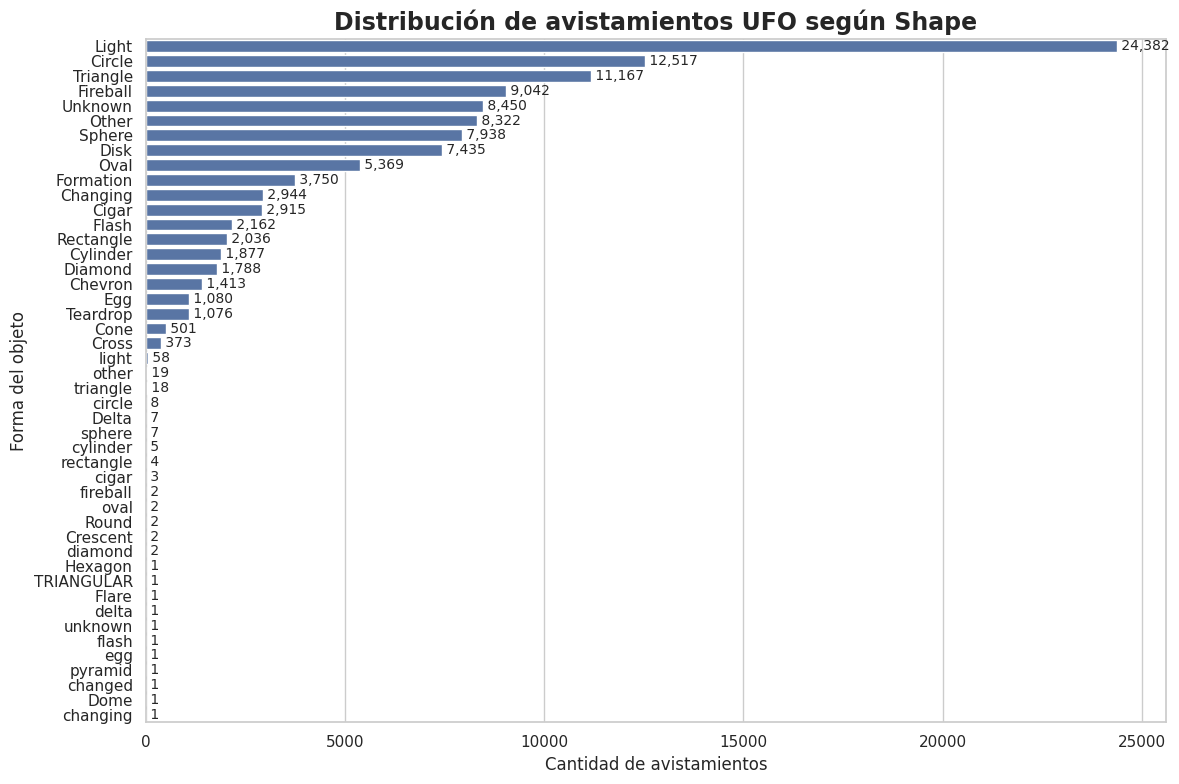

In [3]:
# ============================================
# ANÁLISIS DE LA VARIABLE OBJETIVO: SHAPE
# ============================================

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# --------------------------------------------
# Información general
# --------------------------------------------

print("========== VARIABLE OBJETIVO: SHAPE ==========")

print(f"\nCantidad de variables del dataset: {len(df.columns)}")
print(f"Cantidad de clases de Shape: {df['shape'].nunique()}")

print("\nFormas de OVNI registradas:")
print(df["shape"].dropna().unique())

# --------------------------------------------
# Frecuencia de cada clase
# --------------------------------------------

frecuencias = (
    df["shape"]
    .value_counts()
    .sort_values(ascending=False)
)

print("\nCantidad de frecuencia de registros por forma:")
display(frecuencias.to_frame("Cantidad de registros"))

# --------------------------------------------
# Gráfico con Seaborn
# --------------------------------------------

plt.figure(figsize=(12, 8))

sns.barplot(
    x=frecuencias.values,
    y=frecuencias.index
)

plt.title(
    "Distribución de avistamientos UFO según Shape",
    fontsize=17,
    fontweight="bold"
)

plt.xlabel("Cantidad de avistamientos")
plt.ylabel("Forma del objeto")

# Mostrar valores
for i, valor in enumerate(frecuencias.values):
    plt.text(
        valor,
        i,
        f" {valor:,}",
        va="center",
        fontsize=10
    )

plt.tight_layout()
plt.show()

# TIPOS DE VARIABLES - CANTIDAD DE REGISTROS NULOS Y DUPLICADOS - ESTADÍSTICAS

========== INFORMACIÓN DEL DATASET ==========

Cantidad de registros: 120,785
Cantidad de variables: 9

========== NOMBRES DE LAS VARIABLES ==========
1. id
2. occurred_date_time
3. city
4. state
5. shape
6. duration
7. summary
8. details_url
9. posted_date

========== TIPOS DE DATOS ==========
id                     int64
occurred_date_time    object
city                  object
state                 object
shape                 object
duration              object
summary               object
details_url           object
posted_date           object
dtype: object

========== REGISTROS DUPLICADOS ==========

🔹 REGISTROS DUPLICADOS
   0 registros duplicados





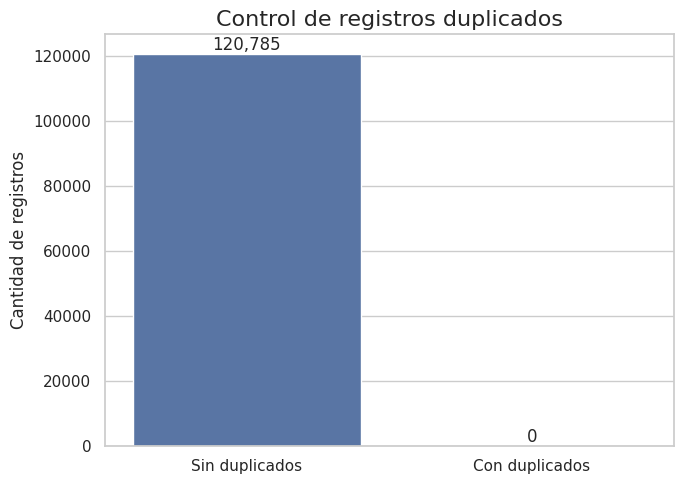


========== VALORES NULOS ==========


,Valores nulos
state,8714
duration,4372
shape,4098
city,261
occurred_date_time,61
summary,37


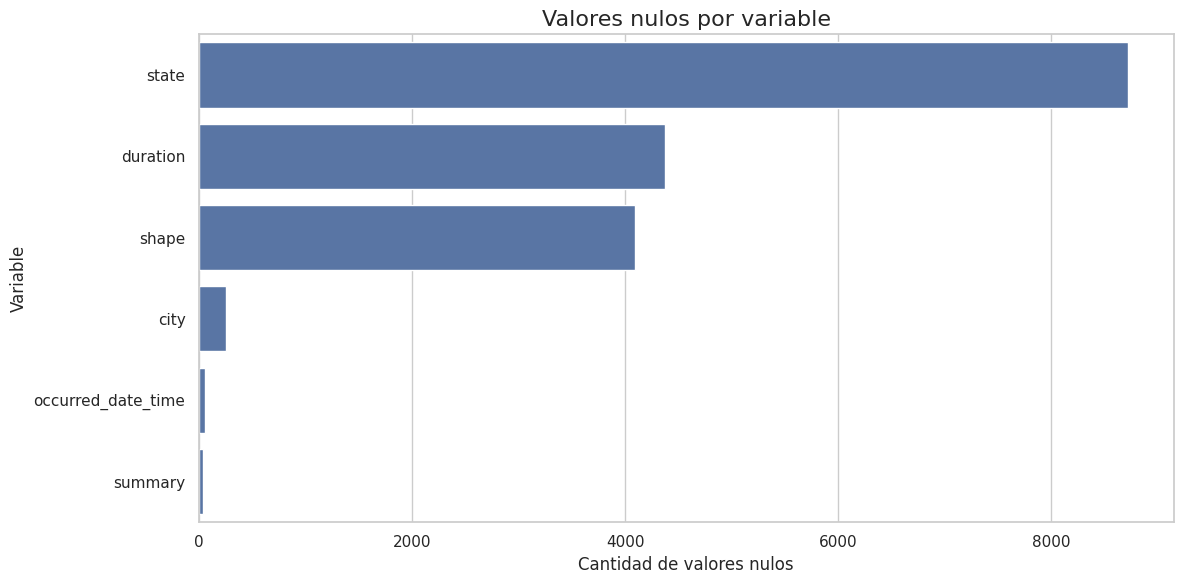


========== RESUMEN ESTADÍSTICO ==========


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,120785.0,NaN,NaN,NaN,75871.788169,41012.029911,111.0,41899.0,76463.0,110911.0,147520.0
occurred_date_time,120724,102842,11/7/15 18:00,104,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city,120524,25918,Seattle,676,NaN,NaN,NaN,NaN,NaN,NaN,NaN
state,112071,70,CA,13656,NaN,NaN,NaN,NaN,NaN,NaN,NaN
shape,116687,46,Light,24382,NaN,NaN,NaN,NaN,NaN,NaN,NaN
duration,116413,12207,5 minutes,7286,NaN,NaN,NaN,NaN,NaN,NaN,NaN
summary,120748,119772,((NUFORC Note: No information provided by wit...,36,NaN,NaN,NaN,NaN,NaN,NaN,NaN
details_url,120785,120785,http://www.nuforc.org/webreports/107/S107717.html,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
posted_date,120785,567,12/12/09,1627,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
# Exploración inicial del dataset

print("========== INFORMACIÓN DEL DATASET ==========")
print(f"\nCantidad de registros: {df.shape[0]:,}")
print(f"Cantidad de variables: {df.shape[1]}")
print("\n========== NOMBRES DE LAS VARIABLES ==========")
for i, columna in enumerate(df.columns, start=1):
    print(f"{i}. {columna}")

print("\n========== TIPOS DE DATOS ==========")
print(df.dtypes)

print("\n========== REGISTROS DUPLICADOS ==========")
# Duplicados
duplicados = df.duplicated().sum()
print("\n🔹 REGISTROS DUPLICADOS")
print(f"   {duplicados:,} registros duplicados")
print("\n" * 2)

duplicados = df.duplicated().sum()
resultado = pd.DataFrame({
    "Estado": ["Sin duplicados", "Con duplicados"],
    "Cantidad": [
        len(df) - duplicados,
        duplicados
    ]
})

plt.figure(figsize=(7, 5))

sns.barplot(
    data=resultado,
    x="Estado",
    y="Cantidad"
)

plt.title("Control de registros duplicados", fontsize=16)
plt.xlabel("")
plt.ylabel("Cantidad de registros")

for i, valor in enumerate(resultado["Cantidad"]):
    plt.text(i, valor, f"{valor:,}", ha="center", va="bottom")

plt.tight_layout()
plt.show()

print("\n========== VALORES NULOS ==========")

# Estilo visual
sns.set_theme(style="whitegrid")

# Valores nulos

nulos = df.isnull().sum().sort_values(ascending=False)

display(
    nulos[nulos > 0]
    .to_frame("Valores nulos")
    .style.background_gradient(cmap="Reds")
)
print("\n" * 2)

# ============================================
# VISUALIZACIÓN DE VALORES NULOS CON BARRAS
# ============================================

plt.figure(figsize=(12, 6))

nulos = df.isnull().sum()
nulos = nulos[nulos > 0].sort_values(ascending=False)

sns.barplot(
    x=nulos.values,
    y=nulos.index
)

plt.title("Valores nulos por variable", fontsize=16)
plt.xlabel("Cantidad de valores nulos")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()



print("\n========== RESUMEN ESTADÍSTICO ==========")
display(df.describe(include="all").T)


#VISUALIZACIÓN DEL RANGO DE AÑOS OBSERVADOS — ORIGINAL

---

##Análisis de la cobertura temporal del dataset

En esta etapa se examina el intervalo temporal.

El análisis permite conocer la extensión cronológica de las observaciones y detectar posibles anomalías temporales, como fechas futuras, errores de registro o valores que requieran una revisión antes del entrenamiento del modelo predictivo.




In [5]:
# Crear temporalmente la columna 'year' extrayéndola de occurred_date_time para el análisis previo
temp_years = pd.to_datetime(df['occurred_date_time'], errors='coerce').dt.year

# Ver el año mínimo y máximo antes de filtrar
min_year = temp_years.min()
max_year = temp_years.max()

print(f"Rango de años original: desde {min_year} hasta {max_year}")

# Si querés ver cuántos registros hay por año o un resumen estadístico
print("\nResumen estadístico de la columna year:")
print(temp_years.describe())

Rango de años original: desde 1962.0 hasta 2075.0

Resumen estadístico de la columna year:
count    120610.000000
mean       2009.803491
std          13.096992
min        1962.000000
25%        2004.000000
50%        2010.000000
75%        2014.000000
max        2075.000000
Name: occurred_date_time, dtype: float64



#LIMPIEZA Y ESTANDARIZACIÓN DE DATOS DEL DATASET

---

##Preparación y control de calidad de los datos

- **Estandarizar variables categóricas:** unificar formatos y corregir inconsistencias en categorías como `shape`.
- **Validar tipos de datos:** comprobar que cada columna tenga el formato apropiado para su contenido.
- **Preservar la información útil:** evitar la eliminación indiscriminada de registros o variables relevantes para el estudio.

###Procedimiento de trabajo

1. Detección y evaluación de registros duplicados.
2. Normalización de formatos y categorías.
3. Validación de variables temporales y numéricas.

---


### ESTANDARIZAR NOMBRES DE COLUMNAS SI TIENEN ESPACIOS O CARACTERES ESPECIALES

In [6]:
# Aplicar la limpieza de nombres de columnas
df.columns = df.columns.str.strip().str.lower()

# Mostrar la lista actualizada de columnas del DataFrame
print('--- Columnas estandarizadas ---')
print(list(df.columns))

--- Columnas estandarizadas ---
['id', 'occurred_date_time', 'city', 'state', 'shape', 'duration', 'summary', 'details_url', 'posted_date']


###DICCIONARIO PARA ESTANDARIZAR NOMBRES DE COLUMNA DE VARIABLE OBJETIVO (`shape` - `forma`)

In [7]:
# Diccionario para unificar variaciones de shape
reemplazos_shape = {
    # Minúsculas a su formato con mayúscula inicial
    "light": "Light",
    "other": "Other",
    "triangle": "Triangle",
    "circle": "Circle",
    "sphere": "Sphere",
    "cylinder": "Cylinder",
    "rectangle": "Rectangle",
    "cigar": "Cigar",
    "fireball": "Fireball",
    "oval": "Oval",
    "delta": "Delta",
    "unknown": "Unknown",
    "flash": "Flash",
    "egg": "Egg",

    # Sinónimos o variantes especiales
    "TRIANGULAR": "Triangle",
    "changed": "Changing",
    "changing": "Changing"
}

# Aplicar el reemplazo en la columna shape usando el DataFrame correcto ('df')
df["shape"] = df["shape"].replace(reemplazos_shape)

# Ver el resultado ordenado
df["shape"].value_counts()

,count
shape,
Light,24440
Circle,12525
Triangle,11186
Fireball,9044
Unknown,8451
Other,8341
Sphere,7945
Disk,7435
Oval,5371


# ESTANDARIZAR DURACIÓN A VALORES NUMÉRICOS


##COLUMNA `duration_seconds` — CATEGORIZACIÓN (*BINNING*)

---

###Transformación de la duración del avistamiento en categorías

La variable `duration_seconds` representa la duración de un avistamiento OVNI expresada en segundos. Para facilitar su interpretación, se puede aplicar una técnica de transformación denominada **categorización o *binning***, que consiste en agrupar los valores numéricos continuos en intervalos definidos.

Esta transformación permite analizar la duración mediante categorías temporales y explorar patrones que podrían resultar útiles para comprender el comportamiento de los registros.


###Criterio de categorización - según https://canadianuforeport.ca/

The Canadian UFO Survey es un sitio NO oficial donde categoriza las duraciones de los avistamientos.

Los intervalos deben definirse según la distribución real de los datos y los objetivos del análisis. Por ejemplo, se pueden considerar categorías como:

- 🟢 **Muy corto:** hasta 10 segundos.
- 🔵 **Corto:** más de 10 y hasta 60 segundos.
- 🟡 **Medio:** más de 60 y hasta 300 segundos.
- 🟠 **Largo:** más de 300 y hasta 1.800 segundos.
- 🔴 **Muy largo:** más de 1.800 segundos.

*Estos intervalos son una propuesta inicial y deben validarse con la distribución del dataset.*


In [8]:
import pandas as pd
import numpy as np
import re


# 2. Función precisa para limpiar y convertir la duración a segundos
def limpiar_duracion_exacta(val):
    if pd.isna(val):
        return np.nan

    val_str = str(val).lower().strip()

    # Si contiene minutos (min, minute, minutes)
    if 'min' in val_str:
        # Extraemos únicamente el número antes de la palabra minuto
        match = re.search(r'([\d\.]+)', val_str)
        if match:
            try:
                num = float(match.group(1))
                return num * 60  # 5 minutos * 60 = 300 segundos exactos
            except:
                return np.nan

    # Si contiene segundos (sec, second, seconds)
    if 'sec' in val_str:
        match = re.search(r'([\d\.]+)', val_str)
        if match:
            try:
                return float(match.group(1)) # Los segundos se quedan igual
            except:
                return np.nan

    # Por si acaso hay algún número suelto sin texto
    try:
        return float(val_str)
    except:
        return np.nan

# 3. Aplicar la función a la columna duration para crear 'duration_seconds'
df['duration_seconds'] = df['duration'].apply(limpiar_duracion_exacta)

# 4. Guardar los cambios en el dataset
output_path = 'clean_ufo_data.csv'
df.to_csv(output_path, index=False)

print("¡Conversión de duración realizada con éxito!")
display(df[['duration', 'duration_seconds']].head(10))

¡Conversión de duración realizada con éxito!


,duration,duration_seconds
0,5 minutes,300.0
1,20 minutes,1200.0
2,20 seconds,20.0
3,2 minutes,120.0
4,45 minutes,2700.0
5,2 minutes,120.0
6,2 minutes,120.0
7,5 minutes,300.0
8,5 seconds,5.0
9,60 seconds,60.0


In [9]:
import pandas as pd
import numpy as np

# 1. Creamos un DataFrame de ejemplo
data = {'duration_seconds': [15, 120, 900, 2500, np.nan, 45, 600, 3600]}
df = pd.DataFrame(data)

# 2. Definimos los bins y las etiquetas
bins = [-1, 60, 300, 1800, float('inf')]
nombres = ['Muy corto (<1m)', 'Corto (1-5m)', 'Medio (5-30m)', 'Largo (>30m)']

# 3. Aplicamos pd.cut
df['duracion_categoria'] = pd.cut(
    df['duration_seconds'], bins=bins, labels=nombres
)

# 4. Mostramos el resultado
print(df)

   duration_seconds duracion_categoria
0              15.0    Muy corto (<1m)
1             120.0       Corto (1-5m)
2             900.0      Medio (5-30m)
3            2500.0       Largo (>30m)
4               NaN                NaN
5              45.0    Muy corto (<1m)
6             600.0      Medio (5-30m)
7            3600.0       Largo (>30m)



#FILTRADO DEL RANGO TEMPORAL DE OBSERVACIONES (1962–2021)

###Se toma la decición de filtrar por este rango por haber más observaciones registradas en el dataset

---

###Selección y validación del período de estudio

En esta etapa se filtran los registros del dataset para conservar únicamente las observaciones comprendidas entre los años **1962 y 2021**, ambos inclusive.

Este procedimiento permite delimitar el período temporal de estudio, excluir registros que se encuentren fuera del intervalo seleccionado y trabajar con un conjunto de datos que cumpla con los criterios cronológicos establecidos para el análisis.

###Criterio de selección

Se conservarán los registros que cumplan la siguiente condición:

**1962 ≤ año de observación ≤ 2021**


In [10]:
# Para solucionar el KeyError, primero recuperamos el DataFrame real que se cargó desde Kaggle originalmente
# Nota: En tu flujo, 'clean_ufo_data.csv' ya fue cargado. Volvemos a leerlo o asignarlo si se perdió la referencia.
try:
    # Si se ejecutó la celda N8rL3uDGTllU, csv_path sigue disponible en el entorno
    df = pd.read_csv(csv_path, low_memory=False, on_bad_lines='skip')
    # Re-aplicamos la limpieza de columnas en minúsculas y reemplazos de shape necesarios
    df.columns = df.columns.str.strip().str.lower()
    df["shape"] = df["shape"].replace(reemplazos_shape)
except NameError:
    print("Por favor, ejecuta primero la celda de carga de datos (N8rL3uDGTllU) para restaurar el dataset original.")

# 1. Extraer el año directamente de 'occurred_date_time' y asegurar que sea numérico
df['year'] = pd.to_datetime(df['occurred_date_time'], errors='coerce').dt.year

# 2. Eliminar/Filtrar los registros entre 2025 y 2075 (nos quedamos con los menores a 2025 y mayores o iguales a 1962)
df_limpio = df[(df['year'] >= 1962) & (df['year'] < 2025)]

# 3. Ver cuántos registros se eliminaron y comprobar el nuevo máximo
print(f"Registros antes de limpiar: {len(df)}")
print(f"Registros después de excluir 2025-2075: {len(df_limpio)}")
print(f"Nuevo año máximo en el dataset: {df_limpio['year'].max()}")

# Reasignar al DataFrame principal si el resultado es correcto
df = df_limpio.copy()

Registros antes de limpiar: 120785
Registros después de excluir 2025-2075: 116565
Nuevo año máximo en el dataset: 2021.0


# RESULTADO: GRÁFICO DE BARRAS DE RANGO DE AÑOS DE OBSERVACIONES DESDE 1962 HASTA 2021

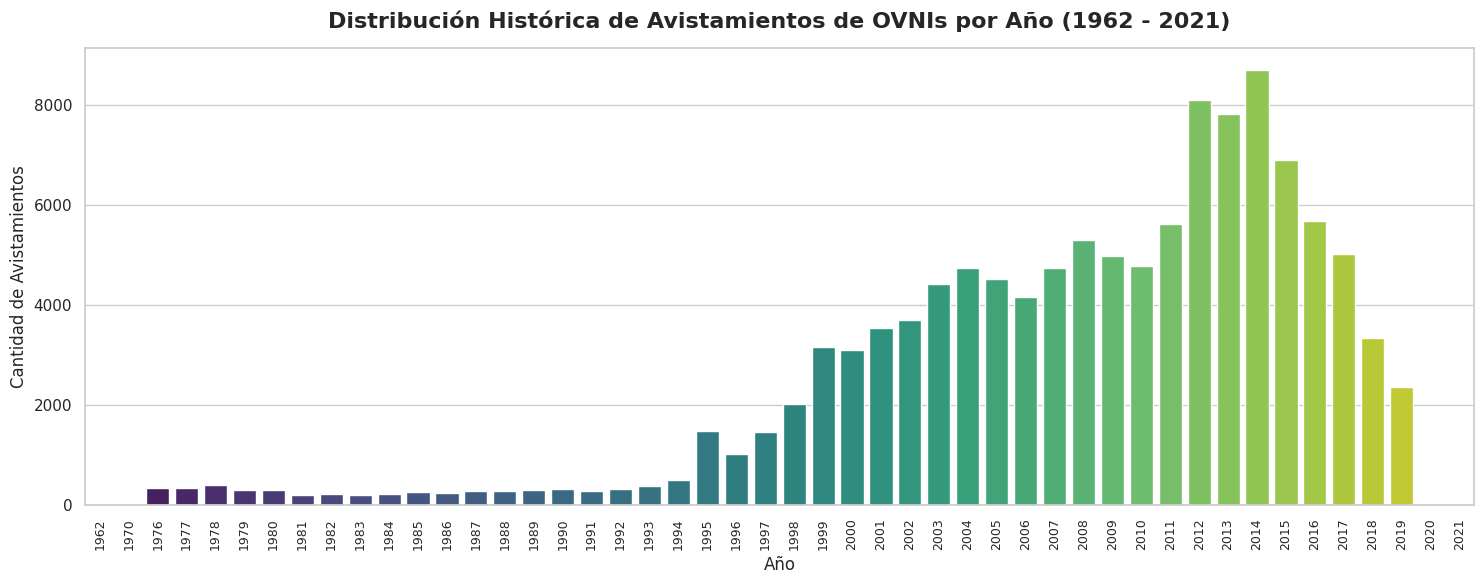

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Agrupar y contar los avistamientos por año usando el DataFrame 'df'
fechas_count = df['year'].value_counts().sort_index()

# Configurar el estilo visual
sns.set_theme(style="whitegrid")
plt.figure(figsize=(15, 6))

# Crear el gráfico de barras
sns.barplot(
    x=fechas_count.index.astype(int),
    y=fechas_count.values,
    palette="viridis"
)

# Personalizar el gráfico
plt.title("Distribución Histórica de Avistamientos de OVNIs por Año (1962 - 2021)", fontsize=16, fontweight="bold", pad=15)
plt.xlabel("Año", fontsize=12)
plt.ylabel("Cantidad de Avistamientos", fontsize=12)
plt.xticks(rotation=90, fontsize=9)  # Rotar los años para que sean legibles

plt.tight_layout()
plt.show()

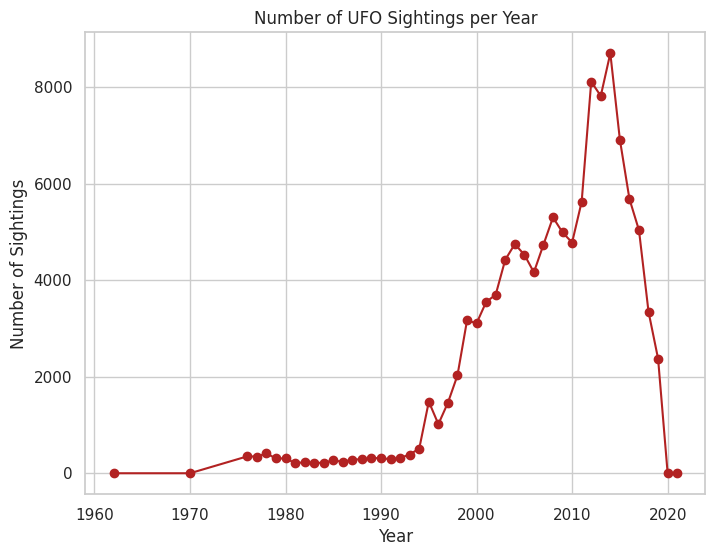

In [12]:
df_year = df['year'].value_counts().reset_index()
df_year.columns = ['year', 'sightings']
df_year = df_year.sort_values('year')

plt.figure(figsize=(8, 6))
plt.plot(df_year['year'], df_year['sightings'], color='firebrick', marker='o')
plt.title('Number of UFO Sightings per Year')
plt.xlabel('Year')
plt.ylabel('Number of Sightings')
plt.show()


#CREACIÓN Y CLASIFICACIÓN DE LOS MESES SEGÚN LAS CUATRO ESTACIONES DEL AÑO (hemisferio norte)

A partir de la fecha de cada avistamiento, se identifica el mes de observación y se lo clasifica en una de las cuatro estaciones: verano, otoño, invierno o primavera.

Esta transformación permite incorporar información estacional al dataset y explorar posibles relaciones entre la época del año y las características de los avistamientos UFO - OVNI.

### Objetivos del procedimiento

- **Identificar el mes:** extraer el mes de la fecha de cada observación.
- **Crear una nueva variable:** incorporar una columna denominada `season`.
- **Clasificar los meses:** asignar cada mes a su estación correspondiente.
- **Analizar la distribución:** conocer la cantidad de avistamientos registrados en cada estación.
- **Explorar patrones estacionales:** evaluar si existen diferencias en la frecuencia de los reportes según la época del año.

### Criterio de clasificación — Hemisferio norte

| ☀️ Verano (*Summer*) | Junio, julio y agosto |
| 🍂 Otoño (*Autumn/Fall*) | Septiembre, octubre y noviembre |
| ❄️ Invierno (*Winter*) | Diciembre, enero y febrero |
| 🌸 Primavera (*Spring*) | Marzo, abril y mayo |

###Procedimiento

1. Verificar que la fecha de observación tenga un formato válido.
2. Extraer el mes correspondiente a cada registro.
3. Asignar la estación del año mediante una regla de clasificación.
4. Guardar el resultado en la nueva columna `season`.

---

###Resultado esperado

Obtener una nueva columna categórica denominada `season`, con cuatro valores posibles: `Verano`, `Otoño`, `Invierno` y `Primavera`, que permita estudiar la distribución estacional de los avistamientos y evaluar su utilidad en el modelo de Aprendizaje Automático (*Machine Learning*).


In [13]:
import pandas as pd
import os

# 1. Cargar el dataset desde la ruta original de Kaggle
try:
    # Intentamos usar la variable csv_path que ya tiene la ruta correcta
    df = pd.read_csv(csv_path, low_memory=False, on_bad_lines='skip')
except NameError:
    # Respaldo por si se perdió la variable en el entorno
    print("La variable 'csv_path' no está definida. Cargando desde la ruta por defecto de Kaggle...")
    df = pd.read_csv('/kaggle/input/ufo-sightings/clean_ufo_data.csv', low_memory=False, on_bad_lines='skip')

# Estandarizar columnas a minúsculas para evitar KeyError en pasos posteriores
df.columns = df.columns.str.strip().str.lower()

# 2. Procesar fecha y hora
df['occurred_datetime'] = pd.to_datetime(df['occurred_date_time'], errors='coerce')
df['month'] = df['occurred_datetime'].dt.month

# 3. Crear la columna de meses en palabras
meses_en_palabras = {
    1: 'Enero', 2: 'Febrero', 3: 'Marzo', 4: 'Abril',
    5: 'Mayo', 6: 'Junio', 7: 'Julio', 8: 'Agosto',
    9: 'Septiembre', 10: 'Octubre', 11: 'Noviembre', 12: 'Diciembre'
}
df['month_name'] = df['month'].map(meses_en_palabras)

# 4. Crear la columna de estaciones para el hemisferio norte
def obtener_estacion_norte(mes):
    if mes in [12, 1, 2]:
        return 'Invierno'
    elif mes in [3, 4, 5]:
        return 'Primavera'
    elif mes in [6, 7, 8]:
        return 'Verano'
    elif mes in [9, 10, 11]:
        return 'Otoño'
    else:
        return 'Desconocido'

df['north_season'] = df['month'].apply(obtener_estacion_norte)

# 5. Guardar los cambios en el directorio local de trabajo para que ya exista 'clean_ufo_data.csv'
df.to_csv('clean_ufo_data.csv', index=False)

print("¡Los cambios se han guardado correctamente en 'clean_ufo_data.csv'!")

¡Los cambios se han guardado correctamente en 'clean_ufo_data.csv'!


In [14]:
import pandas as pd
import os

# 1. Cargar el dataset desde la ruta original de Kaggle
try:
    # Intentamos usar la variable csv_path que ya tiene la ruta correcta
    df = pd.read_csv(csv_path, low_memory=False, on_bad_lines='skip')
except NameError:
    # Respaldo por si se perdió la variable en el entorno
    print("La variable 'csv_path' no está definida. Cargando desde la ruta por defecto de Kaggle...")
    df = pd.read_csv('/kaggle/input/ufo-sightings/clean_ufo_data.csv', low_memory=False, on_bad_lines='skip')

# Estandarizar columnas a minúsculas para evitar KeyError en pasos posteriores
df.columns = df.columns.str.strip().str.lower()

# 2. Procesar fecha y hora
df['occurred_datetime'] = pd.to_datetime(df['occurred_date_time'], errors='coerce')
df['month'] = df['occurred_datetime'].dt.month

# 3. Crear la columna adicional con los nombres de los meses en palabras ('month_category')
meses_en_palabras = {
    1: 'Enero', 2: 'Febrero', 3: 'Marzo', 4: 'Abril',
    5: 'Mayo', 6: 'Junio', 7: 'Julio', 8: 'Agosto',
    9: 'Septiembre', 10: 'Octubre', 11: 'Noviembre', 12: 'Diciembre'
}
df['month_category'] = df['month'].map(meses_en_palabras)

# 4. Crear la columna de estaciones para el hemisferio norte
def obtener_estacion_norte(mes):
    if mes in [12, 1, 2]:
        return 'Invierno'
    elif mes in [3, 4, 5]:
        return 'Primavera'
    elif mes in [6, 7, 8]:
        return 'Verano'
    elif mes in [9, 10, 11]:
        return 'Otoño'
    else:
        return 'Desconocido'

df['north_season'] = df['month'].apply(obtener_estacion_norte)

# 5. Guardar los cambios en el directorio local de trabajo para que se actualice 'clean_ufo_data.csv'
df.to_csv('clean_ufo_data.csv', index=False)

print("¡Los cambios se han guardado correctamente en 'clean_ufo_data.csv' con la columna 'month_category'!")
display(df[['occurred_date_time', 'month', 'month_category', 'north_season']].head())

¡Los cambios se han guardado correctamente en 'clean_ufo_data.csv' con la columna 'month_category'!


,occurred_date_time,month,month_category,north_season
0,7/12/19 09:20,7.0,Julio,Verano
1,7/12/19 03:30,7.0,Julio,Verano
2,7/11/19 22:40,7.0,Julio,Verano
3,7/11/19 22:10,7.0,Julio,Verano
4,7/11/19 22:00,7.0,Julio,Verano


# RESULTADO: GRÁFICO DE BARRAS DE LOS MESES - ESTACIONES DEL AÑO (EN EL HEMISFERIO NORTE).

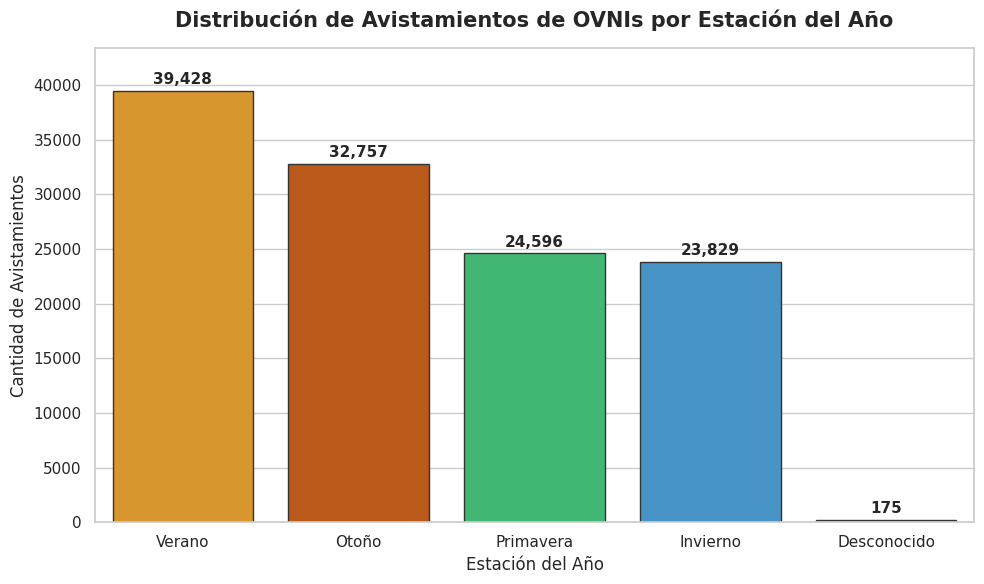

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

# Asegurar que tenemos el mes disponible
if 'month' not in df.columns and 'occurred_datetime' in df.columns:
    df['month'] = df['occurred_datetime'].dt.month

# Definir el mapeo de estaciones para el hemisferio norte
# Invierno: Dic (12), Ene (1), Feb (2)
# Primavera: Mar (3), Abr (4), May (5)
# Verano: Jun (6), Jul (7), Ago (8)
# Otoño: Sep (9), Oct (10), Nov (11)
def obtener_estacion(mes):
    if mes in [12, 1, 2]:
        return 'Invierno'
    elif mes in [3, 4, 5]:
        return 'Primavera'
    elif mes in [6, 7, 8]:
        return 'Verano'
    elif mes in [9, 10, 11]:
        return 'Otoño'
    else:
        return 'Desconocido'

# Crear la columna 'estacion'
df['estacion'] = df['month'].apply(obtener_estacion)

# Calcular la frecuencia de avistamientos por estación
estaciones_count = df['estacion'].value_counts()

# Configurar el estilo visual
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# Paleta de colores representativa de las estaciones (Verano: Amarillo/Naranja, Otoño: Marrón/Rojo, Primavera: Verde, Invierno: Azul)
colores_estaciones = {
    'Verano': '#f39c12',     # Naranja cálido
    'Otoño': '#d35400',      # Marrón rojizo
    'Primavera': '#2ecc71',  # Verde brillante
    'Invierno': '#3498db',   # Azul frío
    'Desconocido': '#95a5a6' # Gris
}

colores_ordenados = [colores_estaciones.get(est, '#95a5a6') for est in estaciones_count.index]

# Crear el gráfico de barras
ax = sns.barplot(
    x=estaciones_count.index,
    y=estaciones_count.values,
    palette=colores_ordenados,
    edgecolor=".2"
)

# Personalizar el gráfico
plt.title("Distribución de Avistamientos de OVNIs por Estación del Año", fontsize=15, fontweight="bold", pad=15)
plt.xlabel("Estación del Año", fontsize=12)
plt.ylabel("Cantidad de Avistamientos", fontsize=12)

# Añadir las etiquetas de datos sobre cada barra
for p in ax.patches:
    ax.annotate(
        f'{int(p.get_height()):,}',
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha='center',
        va='baseline',
        fontsize=11,
        fontweight='bold',
        xytext=(0, 5),
        textcoords='offset points'
    )

# Ajustar el límite superior del eje Y para dar espacio a los textos
plt.ylim(0, estaciones_count.max() * 1.1)
plt.tight_layout()
plt.show()

### Podemos observar una clara distribución estacional en los reportes de avistamientos en el hemisferio norte:

Verano (35,960 avistamientos): Es, por un margen significativo, la estación con mayor cantidad de reportes acumulados. Esto es muy común en los análisis de este tipo de fenómenos debido a que en verano la gente suele pasar más tiempo al aire libre durante la noche.
Otoño (30,931 avistamientos): Se ubica en segundo lugar, manteniendo una cifra bastante alta de avistamientos.
Primavera (23,170 avistamientos) e Invierno (22,577 avistamientos): Son las épocas del año con menor cantidad de registros, manteniéndose ambas en niveles muy similares.


# CREACIÓN DE UNA COLUMNA PARA CLASIFICAR LOS AVISTAMIENTOS POR FRANJA HORARIA DEL DÍA

En esta etapa se crea una nueva variable categórica que permite clasificar los avistamientos OVNI según la franja horaria en la que fueron reportados.

A partir de la hora registrada en el dataset, se asigna cada observación a una categoría temporal. Esta transformación facilita el análisis de la distribución de los avistamientos a lo largo del día y permite explorar posibles patrones relacionados con el horario de ocurrencia.

###Objetivos del procedimiento

- **Identificar la hora:** extraer la hora correspondiente a cada observación.
- **Crear una nueva variable:** incorporar una columna denominada `tim.
- **Clasificar las franjas horarias:** agrupar los registros en categorías temporales.
- **Analizar la distribución:** identificar las franjas con mayor y menor cantidad de reportes.
- **Explorar patrones temporales:** evaluar la utilidad de esta característica para el análisis exploratorio y el modelo predictivo.

###Criterio de clasificación

| Franja horaria | Intervalo |
|---|---|
| 🌙 Madrugada (*Late Night*) | 00:00 a 05:59 |
| 🌅 Mañana (*Morning*) | 06:00 a 11:59 |
| ☀️ Tarde (*Afternoon*) | 12:00 a 17:59 |
| 🌆 Noche (*Evening/Night*) | 18:00 a 23:59 |

### Procedimiento

1. Verificar que la fecha y hora de cada observación tengan un formato válido.
2. Extraer la hora de la observación.
3. Asignar la franja horaria según los intervalos definidos.
4. Guardar la clasificación en la nueva columna `time_of_day`.
5. Comprobar los resultados y visualizar la frecuencia de registros por categoría.


###Resultado esperado

Obtener una nueva columna categórica `time_of_day`, con cuatro clases —`Late Night`, `Morning`, `Afternoon` y `Evening/Night`— para analizar la distribución horaria de los avistamientos y explorar su relación con otras variables del dataset.


In [16]:
import pandas as pd
import numpy as np

# 1. Creamos un DataFrame de ejemplo con algunas horas y un valor nulo (NaN)
data = {'hour': [1, 5, 8, 11, 14, 17, 19, 23, np.nan]}
df = pd.DataFrame(data)

# 2. Tu función para categorizar las horas
def categorizar_hora(hora):
  if pd.isna(hora):
    return 'Desconocido'
  if 0 <= hora < 6:
    return 'Madrugada'
  elif 6 <= hora < 12:
    return 'Mañana'
  elif 12 <= hora < 18:
    return 'Tarde'
  else:
    return 'Noche'

# 3. Aplicamos la función a la columna 'hour'
df['franja_horaria'] = df['hour'].apply(categorizar_hora)

# 4. Mostramos el resultado por consola
print(df)

   hour franja_horaria
0   1.0      Madrugada
1   5.0      Madrugada
2   8.0         Mañana
3  11.0         Mañana
4  14.0          Tarde
5  17.0          Tarde
6  19.0          Noche
7  23.0          Noche
8   NaN    Desconocido



#CREACIÓN DE LA COLUMNA `state` — AGRUPACIÓN GEOGRÁFICA

En esta etapa se analiza la variable geográfica `state`, que identifica el estado o la región administrativa en Estados Unidos asociada a cada avistamiento OVNI.

El objetivo es organizar y estandarizar la información geográfica para facilitar el análisis de la distribución espacial de los reportes e identificar posibles diferencias entre las regiones representadas en el dataset.


###Procedimiento de trabajo

1. Inspeccionar los valores únicos de la columna `state`.
2. Identificar valores nulos, abreviaturas y posibles inconsistencias.
3. Normalizar los nombres de los estados sin alterar su significado.
4. Evaluar la agrupación de categorías poco frecuentes, si resulta metodológicamente justificada.
5. Verificar la distribución de registros por estado mediante tablas y gráficos.

###Consideraciones metodológicas

- Si el dataset contiene principalmente avistamientos de Estados Unidos, `state` puede representar sus estados y el Distrito de Columbia.
- Los valores faltantes deben distinguirse de las categorías geográficas válidas.
- No se deben agrupar ni eliminar estados arbitrariamente: cualquier agrupación debe responder a un criterio documentado.
- Para modelos de Machine Learning, las categorías geográficas deben codificarse mediante una técnica apropiada, como *One-Hot Encoding*, cuando corresponda.

---

###Resultado esperado

Obtener una variable geográfica `state` consistente y validada, que permita analizar la distribución territorial de los avistamientos OVNI y evaluar el aporte de la ubicación al estudio predictivo.


El campo state tiene muchos estados diferentes. Si haces One-Hot Encoding directo, el modelo tendrá demasiadas columnas con pocos datos.

Cómo descomponerla: Agrupar los estados con menos avistamientos en una categoría genérica como "Otros", o mantener solo los 10 o 15 estados con mayor volumen de reportes.

In [17]:
import pandas as pd
import numpy as np

# Recuperar el DataFrame real desde la copia de seguridad en memoria si fue sobrescrito
try:
    if 'state' not in df.columns:
        if 'df_limpio' in globals():
            df = df_limpio.copy()
            print("✓ DataFrame 'df' restaurado correctamente a partir de 'df_limpio'.")
        elif 'df_antes_grafico' in globals():
            df = df_antes_grafico.copy()
            print("✓ DataFrame 'df' restaurado correctamente a partir de 'df_antes_grafico'.")
except NameError:
    pass

# Asegurar que los nulos en 'state' estén imputados como 'unknown' sobre nuestro DataFrame principal 'df'
df['state'] = df['state'].fillna('unknown')

# Identificar los 10 estados principales
top_states = df['state'].value_counts().nlargest(10).index

# Agrupar el resto en la categoría 'Other'
df['state_grouped'] = df['state'].apply(
    lambda x: x if x in top_states else 'Other'
)

print("✓ Columna 'state_grouped' creada con éxito sobre el dataset real.")
print(df['state_grouped'].value_counts())

✓ DataFrame 'df' restaurado correctamente a partir de 'df_limpio'.
✓ Columna 'state_grouped' creada con éxito sobre el dataset real.
state_grouped
Other      58697
CA         13234
unknown     8305
FL          6450
WA          5796
TX          4777
NY          4515
AZ          4029
PA          3771
IL          3539
OH          3452
Name: count, dtype: int64


# RESULTADO: GRÁFICO COMPARATIVO DE AVISTAMIENTOS POR 'state_grouped'

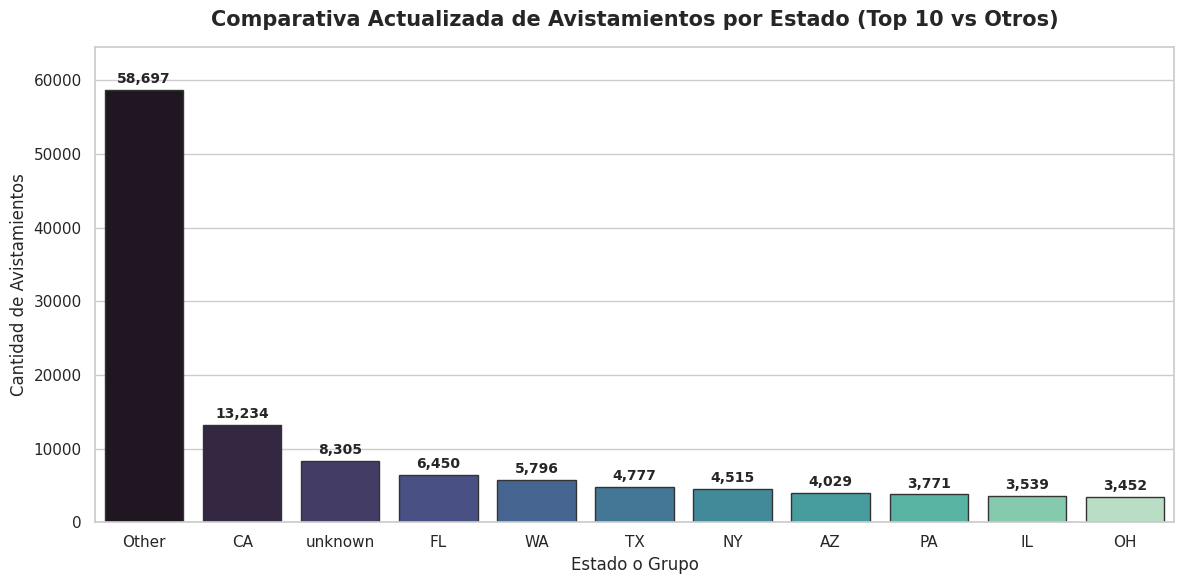

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calcular la frecuencia de avistamientos por estado actualizado
state_counts_actualizado = df['state_grouped'].value_counts()

# 2. Configurar el estilo visual
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))

# 3. Crear el gráfico de barras
ax = sns.barplot(
    x=state_counts_actualizado.index,
    y=state_counts_actualizado.values,
    palette="mako",
    edgecolor=".2"
)

# 4. Personalizar el gráfico
plt.title("Comparativa Actualizada de Avistamientos por Estado (Top 10 vs Otros)", fontsize=15, fontweight="bold", pad=15)
plt.xlabel("Estado o Grupo", fontsize=12)
plt.ylabel("Cantidad de Avistamientos", fontsize=12)

# 5. Añadir las etiquetas con el número exacto sobre cada barra
for p in ax.patches:
    ax.annotate(
        f'{int(p.get_height()):,}',
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha='center',
        va='baseline',
        fontsize=10,
        fontweight='bold',
        xytext=(0, 5),
        textcoords='offset points'
    )

# Ajustar límites y mostrar el gráfico
plt.ylim(0, state_counts_actualizado.max() * 1.1)
plt.tight_layout()
plt.show()

# TRATAMIENTO DE VALORES NULOS

---

###TRATAMIENTO DE VALORES NULOS EN `shape` (forma del objeto volador no identificado)

Como es la variable objetivo, no conviene imputar los valores nulos con la moda ni con "Unknown". Eso modificaría artificialmente la clase que queremos predecir.

La opción más adecuada es eliminar únicamente las filas donde shape es nulo, conservando los demás registros.

---


###TRATAMIENTO DE VALORES NULOS EN `state` Y `city`

Se imputan como "Unknown" para no perder registros en esas categorias.

.

---

###TRATAMIENTO DE VALORES NULOS EN `duration` Y `date_time`

duration: Se conservaron los registros y los nulos se reemplazaron por "unknown".

date_time: Se eliminaron los registros sin una fecha válida.

In [19]:
# ============================================================
# TRATAMIENTO UNIFICADO DE VALORES NULOS (CORREGIDO)
# ============================================================

import pandas as pd
import numpy as np
import re

print("=" * 70)
print("          TRATAMIENTO DE VALORES NULOS")
print("=" * 70)

# Función para estandarizar duración a valores numéricos (reutilizada para evitar KeyError)
def limpiar_duracion(val):
    if pd.isna(val):
        return np.nan
    val_str = str(val).lower().strip()
    if val_str in ['unknown', 'on going', 'nan', 'none', '']:
        return np.nan
    if ':' in val_str:
        partes = val_str.split(':')
        try:
            if len(partes) == 2:
                return float(partes[0]) * 60 + float(partes[1])
            elif len(partes) == 3:
                return float(partes[0]) * 3600 + float(partes[1]) * 60 + float(partes[2])
        except:
            return np.nan
    rango_match = re.search(
        r'([\d\.]+)\s*-\s*([\d\.]+)\s*(second|minute|hour|sec|min|hr)', val_str
    )
    if rango_match:
        try:
            minimo = float(re.sub(r'^[^\d\.]+|[^\d\.]+$', '', rango_match.group(1)))
            maximo = float(re.sub(r'^[^\d\.]+|[^\d\.]+$', '', rango_match.group(2)))
            promedio = (minimo + maximo) / 2
            unidad = rango_match.group(3)
            if 'sec' in unidad:
                return promedio
            elif 'min' in unidad:
                return promedio * 60
            elif 'hour' in unidad or 'hr' in unidad:
                return promedio * 3600
        except:
            return np.nan
    val_str = val_str.replace('>', '').replace('<', '').strip()
    match = re.search(
        r'([\d\.]+)\s*(second|sec|minute|min|hour|hr)', val_str, re.IGNORECASE
    )
    if match:
        try:
            num_str = re.sub(r'^[^\d\.]+|[^\d\.]+$', '', match.group(1))
            num = float(num_str)
            unidad = match.group(2).lower()
            if 'sec' in unidad:
                return num
            elif 'min' in unidad:
                return num * 60
            elif 'hour' in unidad or 'hr' in unidad:
                return num * 3600
        except:
            return np.nan
    try:
        num_str = re.sub(r'^[^\d\.]+|[^\d\.]+$', '', val_str)
        return float(num_str)
    except:
        return np.nan

# ------------------------------------------------------------
# Asegurar existencia de 'duration_seconds'
# ------------------------------------------------------------
if 'duration_seconds' not in df.columns:
    print("⚙️ Creando la columna 'duration_seconds' faltante a partir de 'duration'...")
    df['duration_seconds'] = df['duration'].apply(limpiar_duracion)

# ------------------------------------------------------------
# 1. RESUMEN DE VALORES NULOS ANTES DEL TRATAMIENTO
# ------------------------------------------------------------

nulos_antes = df.isnull().sum()
nulos_antes = nulos_antes[nulos_antes > 0].sort_values(ascending=False)

print("\n========== VALORES NULOS ANTES DEL TRATAMIENTO ==========")
if len(nulos_antes) > 0:
    display(nulos_antes.to_frame("Valores nulos"))
else:
    print("No se detectaron valores nulos iniciales.")

print(f"\nCantidad de registros antes del tratamiento: {len(df):,}")


# ------------------------------------------------------------
# 2. SHAPE - VARIABLE OBJETIVO
# ------------------------------------------------------------
# Como 'shape' es la variable objetivo, no se imputan sus
# valores faltantes. Se eliminan solamente esos registros.

print("\n========== TRATAMIENTO DE SHAPE ==========")

print(f"Valores nulos en shape antes: {df['shape'].isnull().sum():,}")

df = df.dropna(subset=['shape']).copy()

print(f"Valores nulos en shape después: {df['shape'].isnull().sum():,}")


# ------------------------------------------------------------
# 3. CITY, STATE, SUMMARY Y POSTED_DATE
# ------------------------------------------------------------
# Para conservar los registros, los valores faltantes se
# reemplazan por 'unknown'.

print("\n========== TRATAMIENTO DE VARIABLES CATEGÓRICAS ==========")

columnas_unknown = [
    'state',
    'city',
    'summary',
    'posted_date'
]

print("Valores nulos antes:")
print(df[columnas_unknown].isnull().sum())

for columna in columnas_unknown:
    df[columna] = df[columna].fillna('unknown')

print("\nValores nulos después:")
print(df[columnas_unknown].isnull().sum())


# ------------------------------------------------------------
# 4. OCCURRED_DATE_TIME
# ------------------------------------------------------------
# Convertir a formato fecha.
# Los valores que no puedan convertirse serán NaT y se eliminan.

print("\n========== TRATAMIENTO DE OCCURRED_DATE_TIME ==========")

nulos_date_time_antes = df['occurred_date_time'].isnull().sum()

df['occurred_date_time'] = pd.to_datetime(
    df['occurred_date_time'],
    errors='coerce'
)

print(f"Valores nulos antes de la conversión: {nulos_date_time_antes:,}")
print(f"Valores inválidos después de la conversión: "
      f"{df['occurred_date_time'].isnull().sum():,}")

# Eliminar solamente los registros sin fecha válida
df = df.dropna(subset=['occurred_date_time']).copy()

print(f"Valores nulos después del tratamiento: "
      f"{df['occurred_date_time'].isnull().sum():,}")


# ------------------------------------------------------------
# 5. DURATION Y DURATION_SECONDS
# ------------------------------------------------------------
# Para duration se imputa 'unknown'.
# Para duration_seconds se imputa la mediana agrupada por 'shape'
# (o la mediana global como respaldo) y se crea un indicador binario de nulos.

print("\n========== TRATAMIENTO DE DURATION Y DURATION_SECONDS ==========")

print(f"Valores nulos en duration antes: {df['duration'].isnull().sum():,}")
df['duration'] = df['duration'].fillna('unknown')
print(f"Valores nulos en duration después: {df['duration'].isnull().sum():,}")

# 1. Crear indicador binario antes de imputar
df['duration_seconds_isna'] = df['duration_seconds'].isnull().astype(int)

# 2. Imputar la mediana según el 'shape' y mediana global como respaldo
df['duration_seconds'] = df.groupby('shape')['duration_seconds'].transform(
    lambda x: x.fillna(x.median())
)
df['duration_seconds'] = df['duration_seconds'].fillna(df['duration_seconds'].median())

print(f"Valores nulos en duration_seconds final: {df['duration_seconds'].isnull().sum()}")

# ------------------------------------------------------------
# 6. CREACIÓN DE VARIABLES TEMPORALES
# ------------------------------------------------------------

df['year'] = df['occurred_date_time'].dt.year
df['month'] = df['occurred_date_time'].dt.month
df['hour'] = df['occurred_date_time'].dt.hour
df['day_of_week'] = df['occurred_date_time'].dt.dayofweek


# ------------------------------------------------------------
# 7. VERIFICACIÓN FINAL DE VALORES NULOS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("          VERIFICACIÓN FINAL")
print("=" * 70)

nulos_despues = df.isnull().sum()
nulos_despues = nulos_despues[nulos_despues > 0].sort_values(
    ascending=False
)

print(f"\nCantidad de registros después del tratamiento: {len(df):,}")

if len(nulos_despues) == 0:
    print("\n✓ No quedan valores nulos en el dataset.")
else:
    print("\nValores nulos restantes:")
    display(nulos_despues.to_frame("Valores nulos"))


# ------------------------------------------------------------
# 8. RESUMEN COMPARATIVO
# ------------------------------------------------------------

print("\n========== RESUMEN DEL TRATAMIENTO ==========")

print(f"Registros iniciales: 120,785")
print(f"Registros finales:    {len(df):,}")
print(f"Registros eliminados: {120785 - len(df):,}")

print("\nTratamientos realizados:")
print("• shape → eliminación de registros con valores nulos (variable objetivo)")
print("• state → imputación con 'unknown'")
print("• city → imputación con 'unknown'")
print("• summary → imputación con 'unknown'")
print("• posted_date → imputación con 'unknown'")
print("• occurred_date_time → conversión a fecha y eliminación de registros inválidos")
print("• duration → imputación con 'unknown'")
print("• duration_seconds → imputación por mediana agrupada por 'shape' (y mediana global como respaldo)")
print("• duration_seconds_isna → creación de indicador binario para registrar valores originalmente nulos")
print("• year, month, hour y day_of_week → variables temporales derivadas de occurred_date_time")

print("\n✓ Tratamiento de valores nulos finalizado correctamente.")

          TRATAMIENTO DE VALORES NULOS
⚙️ Creando la columna 'duration_seconds' faltante a partir de 'duration'...

========== VALORES NULOS ANTES DEL TRATAMIENTO ==========


,Valores nulos
duration_seconds,13211
duration,4183
shape,3927
city,228
summary,35



Cantidad de registros antes del tratamiento: 116,565

========== TRATAMIENTO DE SHAPE ==========
Valores nulos en shape antes: 3,927
Valores nulos en shape después: 0

========== TRATAMIENTO DE VARIABLES CATEGÓRICAS ==========
Valores nulos antes:
state            0
city           132
summary          9
posted_date      0
dtype: int64

Valores nulos después:
state          0
city           0
summary        0
posted_date    0
dtype: int64

========== TRATAMIENTO DE OCCURRED_DATE_TIME ==========
Valores nulos antes de la conversión: 0
Valores inválidos después de la conversión: 0
Valores nulos después del tratamiento: 0

========== TRATAMIENTO DE DURATION Y DURATION_SECONDS ==========
Valores nulos en duration antes: 2,859
Valores nulos en duration después: 0
Valores nulos en duration_seconds final: 0

          VERIFICACIÓN FINAL

Cantidad de registros después del tratamiento: 112,638

✓ No quedan valores nulos en el dataset.

========== RESUMEN DEL TRATAMIENTO ==========
Registros ini


# TRATAMIENTO DE VALORES ATÍPICOS (*OUTLIERS*)

---

## Identificación, análisis y tratamiento de observaciones extremas

Los valores atípicos (*outliers*) son observaciones que presentan valores considerablemente alejados del comportamiento general de una variable. Pueden deberse a errores de registro, inconsistencias en los datos o fenómenos reales poco frecuentes.

En el dataset de avistamientos OVNI, resulta especialmente importante analizar la variable `duration_seconds`, ya que algunas observaciones pueden presentar duraciones extremadamente cortas o prolongadas.

###Objetivos del análisis

- **Detectar valores extremos:** identificar observaciones que se alejan de la distribución habitual.
- **Examinar la distribución:** analizar la dispersión y la presencia de valores extremos.
- **Aplicar criterios estadísticos:** utilizar métodos como el rango intercuartílico (*IQR*) para detectar posibles outliers.
- **Evaluar su validez:** distinguir entre errores de registro y observaciones extremas potencialmente legítimas.
- **Definir el tratamiento:** decidir si corresponde conservar, corregir, transformar o excluir determinados valores.

###Metodología de análisis

**1. Identificación**

Se examinan las estadísticas descriptivas y se utilizan herramientas visuales, como histogramas y diagramas de caja (*boxplots*), para estudiar la distribución de los datos.

**2. Detección mediante el rango intercuartílico (IQR)**

Se calculan los cuartiles y el rango intercuartílico:

- \(Q1\): primer cuartil.
- \(Q3\): tercer cuartil.
- \(IQR = Q3 - Q1\).

Se consideran posibles valores atípicos aquellos que cumplen:

- Límite inferior: \(Q1 - 1.5 \times IQR\).
- Límite superior: \(Q3 + 1.5 \times IQR\).

**3. Evaluación y tratamiento**

Los valores detectados deben investigarse antes de tomar decisiones. Según el caso, pueden conservarse, corregirse, transformarse o excluirse si existe evidencia de que son inválidos.

### ⚠️ Consideraciones metodológicas

- Un valor extremo no necesariamente es un error.
- Las duraciones muy prolongadas pueden ser reales o reflejar errores en el registro o la interpretación de las unidades.
- La imputación mediante la mediana no elimina por sí misma los valores atípicos existentes.
- Si se utiliza un modelo de regresión para predecir `duration_seconds`, conviene evaluar el efecto de los valores extremos sobre el error predictivo.
- Los límites estadísticos deben calcularse con el conjunto de entrenamiento cuando se utilicen para preparar un modelo, evitando la fuga de información (*data leakage*).




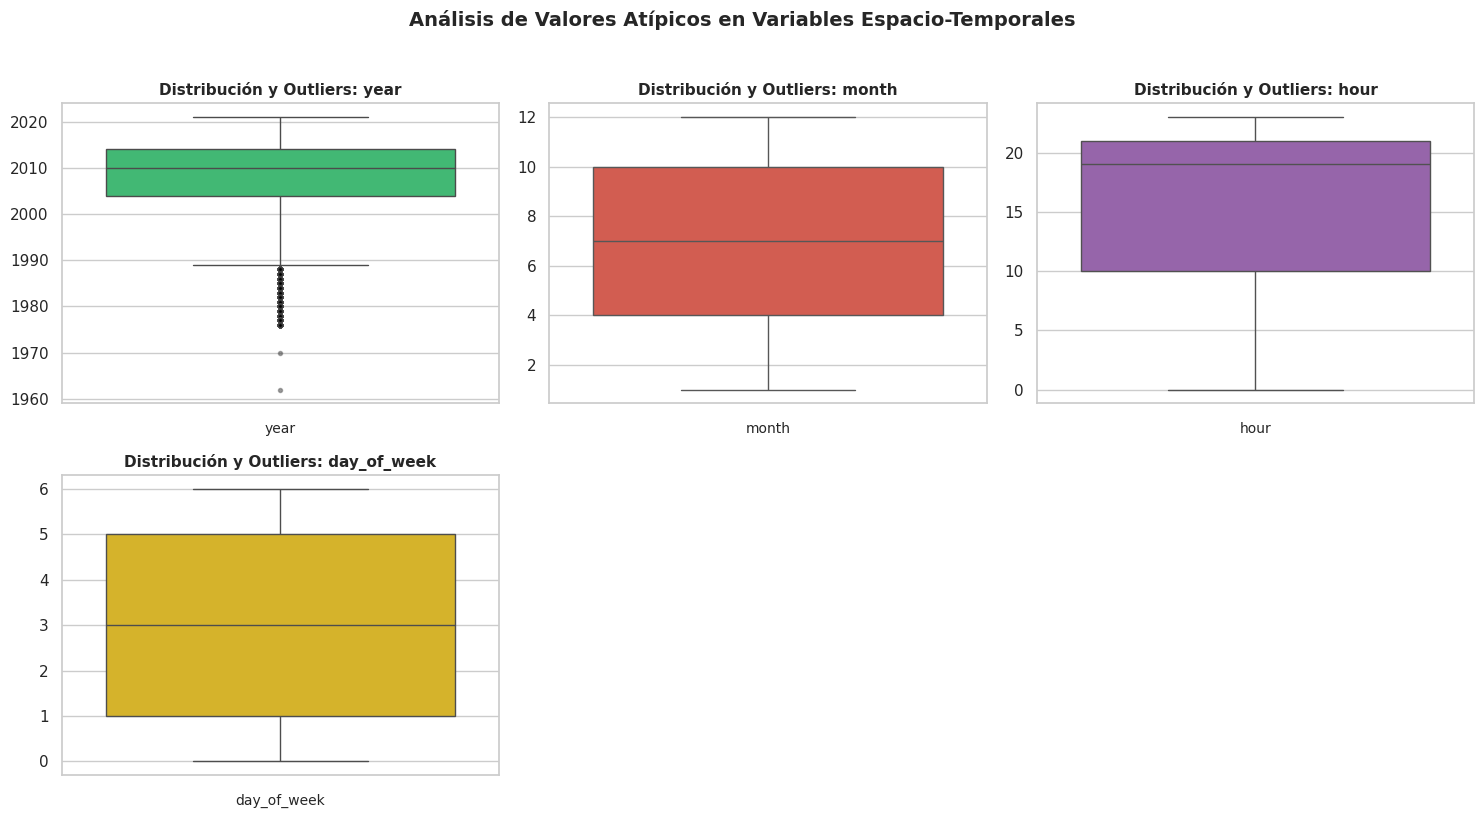

RESUMEN CUANTITATIVO DE OUTLIERS (REGLA DEL IQR)
Variable 'year':
  - Q1 (25%): 2004.00 | Q3 (75%): 2014.00 | IQR: 10.00
  - Límites válidos: [1989.00, 2029.00]
  - Cantidad de Outliers: 3568 (3.17% del total)
Variable 'month':
  - Q1 (25%): 4.00 | Q3 (75%): 10.00 | IQR: 6.00
  - Límites válidos: [-5.00, 19.00]
  - Cantidad de Outliers: 0 (0.00% del total)
Variable 'hour':
  - Q1 (25%): 10.00 | Q3 (75%): 21.00 | IQR: 11.00
  - Límites válidos: [-6.50, 37.50]
  - Cantidad de Outliers: 0 (0.00% del total)
Variable 'day_of_week':
  - Q1 (25%): 1.00 | Q3 (75%): 5.00 | IQR: 4.00
  - Límites válidos: [-5.00, 11.00]
  - Cantidad de Outliers: 0 (0.00% del total)


In [20]:
# ==============================================================================
# VISUALIZACIÓN DE VALORES ATÍPICOS (BOXPLOTS) EN VARIABLES NUMÉRICAS
# ==============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de estilo visual
sns.set_theme(style="whitegrid")
plt.rcParams['font.family'] = 'sans-serif'

# ------------------------------------------------------------------------------
# 1. SELECCIÓN Y PREPARACIÓN DE VARIABLES NUMÉRICAS
# ------------------------------------------------------------------------------
# Usamos 'df' que es el DataFrame que contiene los datos procesados en tu notebook
df_box = df.copy()

# ------------------------------------------------------------------------------
# 2. BOXPLOTS COMPUESTOS PARA VARIABLES ESPACIO-TEMPORALES
# ------------------------------------------------------------------------------
temporal_features = ['city_latitude', 'city_longitude', 'year', 'month', 'hour', 'day_of_week']

# Filtrar únicamente las columnas que existen en el DataFrame
valid_features = [col for col in temporal_features if col in df_box.columns]

fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(15, 8))
axes = axes.flatten()

palette = ['#2ecc71', '#e74c3c', '#9b59b6', '#f1c40f', '#1abc9c', '#e67e22']

for idx, col in enumerate(valid_features):
    sns.boxplot(
        y=df_box[col],
        ax=axes[idx],
        color=palette[idx % len(palette)],
        flierprops=dict(marker='o', markerfacecolor='black', alpha=0.4, markersize=3)
    )
    axes[idx].set_title(f'Distribución y Outliers: {col}', fontsize=11, fontweight='bold')
    axes[idx].set_ylabel('')
    axes[idx].set_xlabel(col, fontsize=10)

# Ocultar subplots vacíos si alguna columna no está presente
for j in range(len(valid_features), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Análisis de Valores Atípicos en Variables Espacio-Temporales', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# 3. CÁLCULO CUANTITATIVO DE OUTLIERS POR EL MÉTODO IQR (Rango Intercuartílico)
# ------------------------------------------------------------------------------
print("="*60)
print("RESUMEN CUANTITATIVO DE OUTLIERS (REGLA DEL IQR)")
print("="*60)

for col in valid_features:
    series = df_box[col].dropna()
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = series[(series < lower_bound) | (series > upper_bound)]
    pct_outliers = (len(outliers) / len(series)) * 100

    print(f"Variable '{col}':")
    print(f"  - Q1 (25%): {Q1:.2f} | Q3 (75%): {Q3:.2f} | IQR: {IQR:.2f}")
    print(f"  - Límites válidos: [{lower_bound:.2f}, {upper_bound:.2f}]")
    print(f"  - Cantidad de Outliers: {len(outliers)} ({pct_outliers:.2f}% del total)")

### **LIMPIEZA DE VALORES ATIPICOS - METODO PERCENTILES (P1-P99)**

Define de antemano qué porcentaje exacto de los extremos deseas recortar (en este caso, un 1% por abajo y un 1% por arriba), protegiendo la gran mayoría de la información.

El método IQR corta de tajo una parte masiva de avistamientos legítimos que superan los 19 minutos. Si vas a limpiar outliers en esta variable para entrenar tus modelos, te conviene utilizar el filtro por percentiles (P1-P99) para no perder datos analíticos importantes.

     LIMPIEZA DE OUTLIERS (PERCENTILES 1% - 99%)
Límite inferior (P1):  1.00 seg
Límite superior (P99): 10800.00 seg (180.00 min)

Registros originales:  112,638
Registros conservados: 111,753 (99.21%)
Outliers eliminados:   885

✓ Limpieza de outliers por percentiles finalizada correctamente.


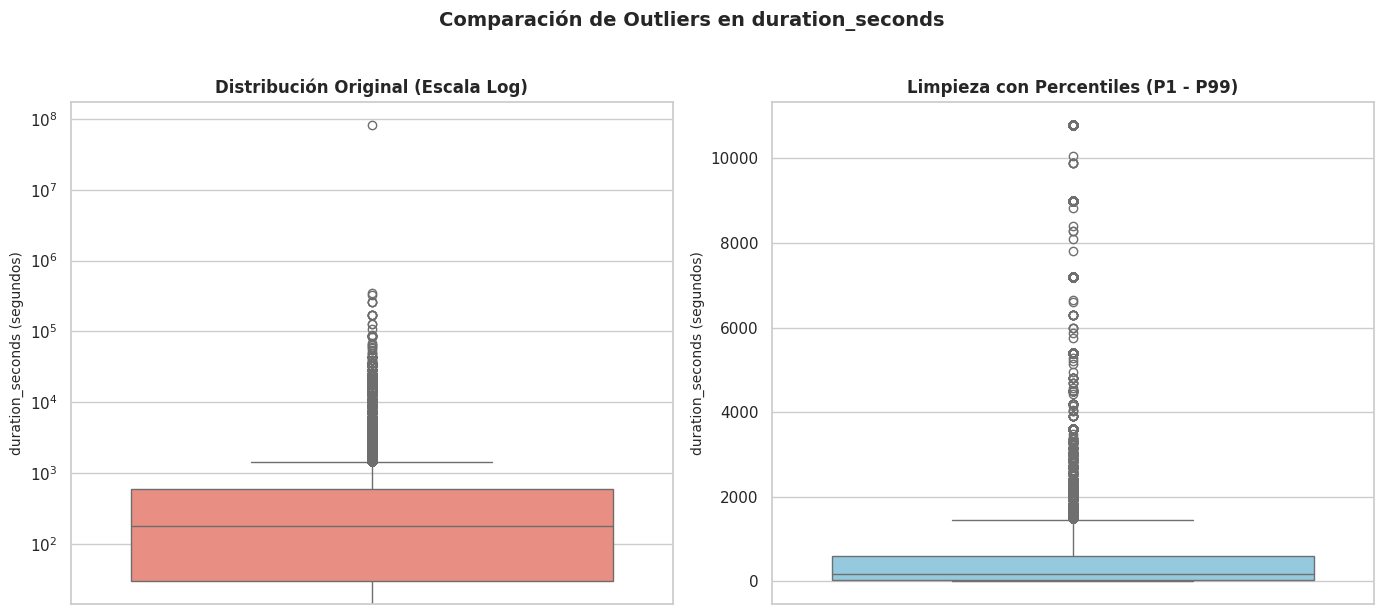

In [21]:
# ============================================================
# LIMPIEZA DE OUTLIERS - MÉTODO DE PERCENTILES (P1 - P99) CON GRÁFICOS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Guardar la cantidad de registros antes de la limpieza y una copia para el gráfico "antes"
registros_antes = len(df)
df_antes_grafico = df.copy()

# 2. Calcular los percentiles 1% y 99% de la variable 'duration_seconds'
limite_inferior = df['duration_seconds'].quantile(0.01)
limite_superior = df['duration_seconds'].quantile(0.99)

print("=" * 60)
print("     LIMPIEZA DE OUTLIERS (PERCENTILES 1% - 99%)")
print("=" * 60)
print(f"Límite inferior (P1):  {limite_inferior:.2f} seg")
print(f"Límite superior (P99): {limite_superior:.2f} seg ({limite_superior / 60:.2f} min)")

# 3. Filtrar el DataFrame conservando solo los valores dentro del rango [P1, P99]
mask = (df['duration_seconds'] >= limite_inferior) & (df['duration_seconds'] <= limite_superior)
df_filtrado = df[mask].copy()

# 4. Mostrar el impacto del filtrado
registros_despues = len(df_filtrado)
registros_eliminados = registros_antes - registros_despues
porcentaje_conservado = (registros_despues / registros_antes) * 100

print(f"\nRegistros originales:  {registros_antes:,}")
print(f"Registros conservados: {registros_despues:,} ({porcentaje_conservado:.2f}%)")
print(f"Outliers eliminados:   {registros_eliminados:,}")

# 5. Actualizar el DataFrame principal
df = df_filtrado

print("\n✓ Limpieza de outliers por percentiles finalizada correctamente.")

# ------------------------------------------------------------
# 6. VISUALIZACIÓN: BOXPLOTS COMPARATIVOS (ANTES VS DESPUÉS)
# ------------------------------------------------------------

plt.figure(figsize=(14, 6))

# Gráfico 1: Antes del filtrado (utilizamos escala logarítmica debido a la alta dispersión)
plt.subplot(1, 2, 1)
sns.boxplot(y=df_antes_grafico['duration_seconds'], color='salmon')
plt.yscale('log') # Escala logarítmica necesaria por los valores extremos originales
plt.title('Distribución Original (Escala Log)', fontsize=12, fontweight='bold')
plt.ylabel('duration_seconds (segundos)', fontsize=10)

# Gráfico 2: Después del filtrado por percentiles (escala normal)
plt.subplot(1, 2, 2)
sns.boxplot(y=df['duration_seconds'], color='skyblue')
plt.title('Limpieza con Percentiles (P1 - P99)', fontsize=12, fontweight='bold')
plt.ylabel('duration_seconds (segundos)', fontsize=10)

plt.suptitle('Comparación de Outliers en duration_seconds', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### **NUEVO ANÁLISIS DE LA VARIABLE OBJETIVO: `shape` (FORMA DEL OBJETO)**

Descartar Light, Other,Unknown,Delta,Crescent,Round,diamond,Hexagon,Flare,Dome,


In [22]:
# Lista de formas que deseas descartar (en minúsculas para abarcar todas las variantes)
formas_a_descartar = [
    "light", "other", "unknown", "delta", "crescent",
    "round", "diamond", "hexagon", "flare", "dome", "pyramid"
]

# Inicializamos df_limpio a partir del DataFrame activo 'df'
df_limpio = df.copy()

# Filtrar el DataFrame descartando los registros cuyas formas estén en la lista
# Usamos .str.lower() y .astype(str) para evitar errores con nulos (NaN) o diferencias de mayúsculas
df_limpio = df_limpio[~df_limpio["shape"].astype(str).str.lower().isin(formas_a_descartar)]

print(f"Registros restantes después de filtrar: {df_limpio.shape[0]:,}")

# Verificar cómo quedó el conteo de formas actualizado
print("\n--- Conteo de formas resultante ---")
display(df_limpio["shape"].value_counts())

Registros restantes después de filtrar: 70,156

--- Conteo de formas resultante ---


,count
shape,
Circle,11992
Triangle,10916
Fireball,8890
Sphere,7603
Disk,6359
Oval,5054
Formation,3673
Changing,2852
Cigar,2640


# RESULTADO: NUEVA VISUALIZACIÓN DE LA VARIABLE OBJETIVO: `shape` (FORMA DEL OBJETO)

========== VARIABLE OBJETIVO: SHAPE (FILTRADO) ==========

Cantidad de registros originales: 111,753
Cantidad de registros después del filtro: 70,156
Cantidad de clases restantes de Shape: 17

Cantidad de registros por forma (filtrado):


,Cantidad de registros
shape,
Circle,11992
Triangle,10916
Fireball,8890
Sphere,7603
Disk,6359
Oval,5054
Formation,3673
Changing,2852
Cigar,2640


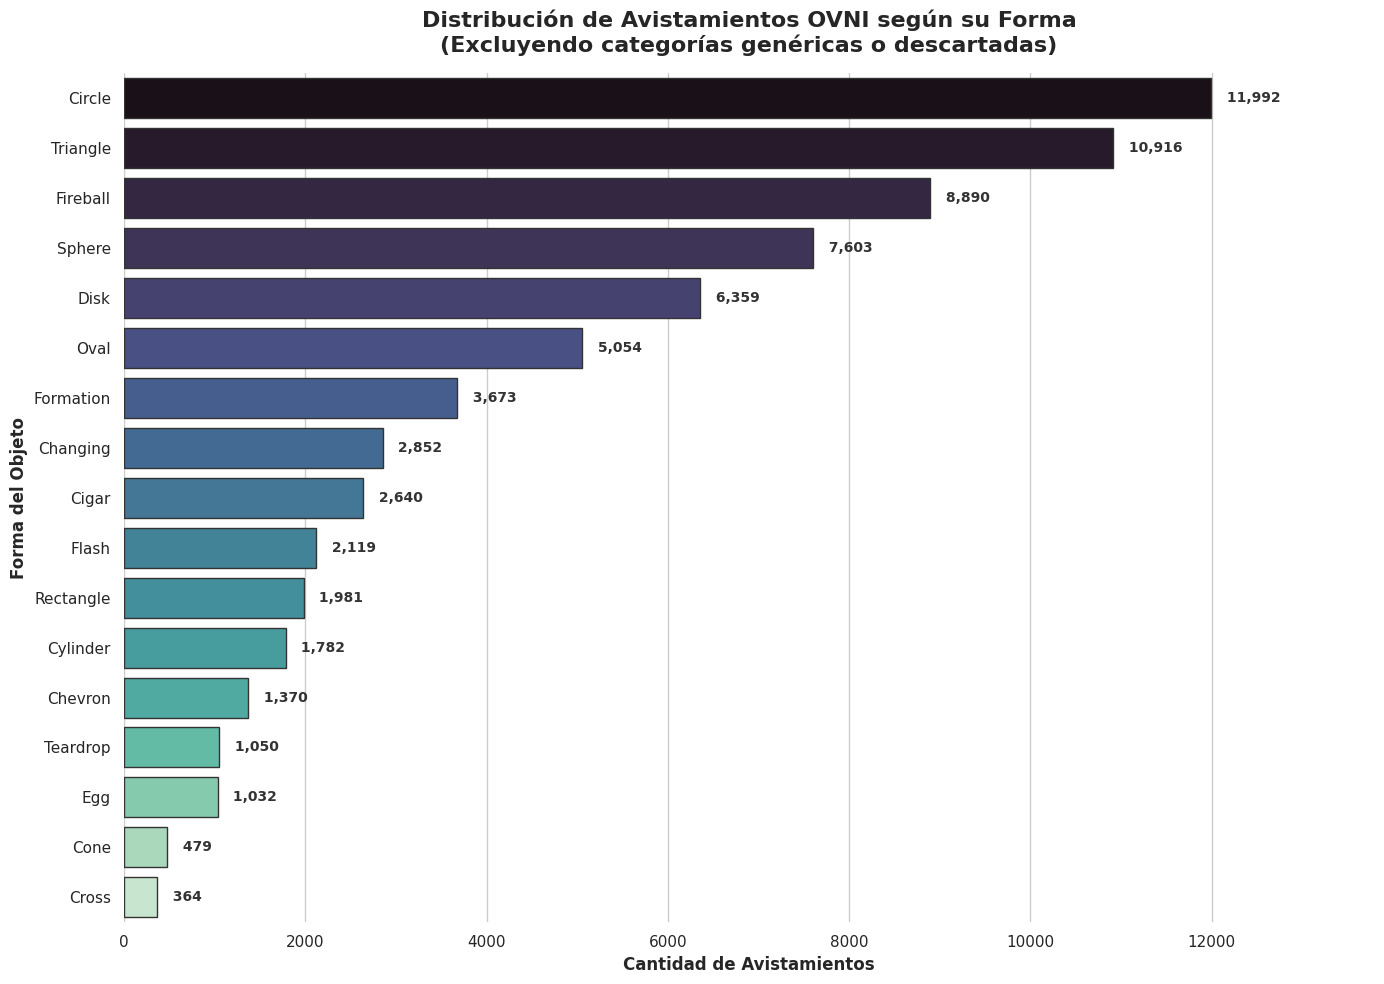

In [23]:
# ============================================
# ANÁLISIS DE LA VARIABLE OBJETIVO: SHAPE (Filtrado)
# ============================================

import matplotlib.pyplot as plt
import seaborn as sns

# Configuración general de estilo
sns.set_theme(style="whitegrid")

# 1. Definir la lista de formas a descartar (en minúsculas)
descartar = [
    "light", "other", "unknown", "delta", "crescent",
    "round", "diamond", "hexagon", "flare", "dome", "pyramid","2013"
]

# 2. Filtrar el DataFrame excluyendo esas formas (insensible a mayúsculas/minúsculas y espacios)
df_filtrado = df[~df["shape"].astype(str).str.lower().str.strip().isin(descartar)].copy()

# --------------------------------------------
# Información general del dataset filtrado
# --------------------------------------------
print("========== VARIABLE OBJETIVO: SHAPE (FILTRADO) ==========")
print(f"\nCantidad de registros originales: {len(df):,}")
print(f"Cantidad de registros después del filtro: {len(df_filtrado):,}")
print(f"Cantidad de clases restantes de Shape: {df_filtrado['shape'].nunique()}")

# --------------------------------------------
# Frecuencia de cada clase restante
# --------------------------------------------
frecuencias = (
    df_filtrado["shape"]
    .value_counts()
    .sort_values(ascending=False)
)

print("\nCantidad de registros por forma (filtrado):")
display(frecuencias.to_frame("Cantidad de registros"))

# --------------------------------------------
# Gráfico con Seaborn (Más vistoso)
# --------------------------------------------
plt.figure(figsize=(14, 10))

ax = sns.barplot(
    x=frecuencias.values,
    y=frecuencias.index,
    hue=frecuencias.index,
    palette="mako",
    legend=False,
    edgecolor=".2"
)

plt.title(
    "Distribución de Avistamientos OVNI según su Forma\n(Excluyendo categorías genéricas o descartadas)",
    fontsize=16,
    fontweight="bold",
    pad=15
)
plt.xlabel("Cantidad de Avistamientos", fontsize=12, fontweight="bold")
plt.ylabel("Forma del Objeto", fontsize=12, fontweight="bold")

# Extender ligeramente el eje X para que los números no se corten
plt.xlim(0, frecuencias.values.max() * 1.15)

# Mostrar valores numéricos al lado de cada barra
for i, valor in enumerate(frecuencias.values):
    ax.text(
        valor + (frecuencias.values.max() * 0.01),
        i,
        f" {valor:,}",
        va="center",
        ha="left",
        fontsize=10,
        fontweight="semibold",
        color="#333333"
    )

sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()


# CONVERSIÓN DE LA VARIABLE `month` A CATEGÓRICA — MESES EN ESPAÑOL

Mapear los números de la columna 'day_of_week' a nombres de días en español

---

##Estandarización y clasificación de los meses del año

En esta etapa se transforma la variable `month`, que representa el mes de cada avistamiento OVNI, en una variable categórica con los nombres de los meses en español.


###Objetivos

- Convertir los valores numéricos de los meses en nombres en español.
- Definir la variable `month` como categórica ordenada.
- Facilitar la visualización de la frecuencia de avistamientos por mes.
- Mantener el orden cronológico de enero a diciembre.
- Preparar la variable para su posterior utilización en el análisis y el modelado predictivo.

###Correspondencia entre valores y categorías

| Valor original | Categoría |
|---:|---|
| 1 | Enero |
| 2 | Febrero |
| 3 | Marzo |
| 4 | Abril |
| 5 | Mayo |
| 6 | Junio |
| 7 | Julio |
| 8 | Agosto |
| 9 | Septiembre |
| 10 | Octubre |
| 11 | Noviembre |
| 12 | Diciembre |

### ⚙️ Consideración metodológica

La variable se define como categórica ordenada (`category`), respetando la secuencia natural de los meses. Los valores faltantes o inválidos deben revisarse para evitar pérdidas involuntarias de información durante la conversión.

---

###Resultado esperado

Obtener una columna `month` con los nombres de los meses en español, ordenados cronológicamente y preparados para analizar la distribución mensual de los avistamientos OVNI.


In [24]:
import os

# 2. Estandarizar los nombres de las columnas
df.columns = df.columns.str.strip().str.lower()

# 3. Procesar la fecha y obtener el mes
df['occurred_datetime'] = pd.to_datetime(
    df['occurred_date_time'],
    errors='coerce'
)

df['month'] = df['occurred_datetime'].dt.month

# 4. Agregar el nombre del mes como nueva columna
meses_en_palabras = {
    1: 'Enero',
    2: 'Febrero',
    3: 'Marzo',
    4: 'Abril',
    5: 'Mayo',
    6: 'Junio',
    7: 'Julio',
    8: 'Agosto',
    9: 'Septiembre',
    10: 'Octubre',
    11: 'Noviembre',
    12: 'Diciembre'
}

df['month_category'] = df['month'].map(meses_en_palabras)

# 5. Agregar la estación del hemisferio norte
def obtener_estacion_norte(mes):
    if pd.isna(mes):
        return 'Desconocido'
    elif mes in [12, 1, 2]:
        return 'Invierno'
    elif mes in [3, 4, 5]:
        return 'Primavera'
    elif mes in [6, 7, 8]:
        return 'Verano'
    elif mes in [9, 10, 11]:
        return 'Otoño'
    return 'Desconocido'

df['north_season'] = df['month'].apply(obtener_estacion_norte)

# 6. Guardar el dataset actualizado con las columnas adicionales en el directorio local de Colab
output_path = 'clean_ufo_data.csv'
df.to_csv(output_path, index=False)

# 7. Verificar los cambios
print("Dataset actualizado correctamente.")
print(f"Cantidad de filas: {len(df)}")
print(f"Columnas agregadas: month, month_category, north_season")
print(f"Archivo guardado en: {os.path.abspath(output_path)}")

display(
    df[['occurred_date_time', 'month',
        'month_category', 'north_season']].head()
)

Dataset actualizado correctamente.
Cantidad de filas: 111753
Columnas agregadas: month, month_category, north_season
Archivo guardado en: /content/clean_ufo_data.csv


,occurred_date_time,month,month_category,north_season
0,2019-07-12 09:20:00,7,Julio,Verano
1,2019-07-12 03:30:00,7,Julio,Verano
2,2019-07-11 22:40:00,7,Julio,Verano
3,2019-07-11 22:10:00,7,Julio,Verano
4,2019-07-11 22:00:00,7,Julio,Verano


In [25]:
# 8. Mapear los números de la columna 'day_of_week' a nombres de días en español
# (Asumiendo que day_of_week usa 0=Lunes, 1=Martes ... 6=Domingo, o 1=Lunes ... 7=Domingo.
# El estándar común de pandas .dt.dayofweek es 0=Lunes a 6=Domingo).

dias_en_palabras = {
    0: 'Lunes',
    1: 'Martes',
    2: 'Miércoles',
    3: 'Jueves',
    4: 'Viernes',
    5: 'Sábado',
    6: 'Domingo'
}

# Si tu columna day_of_week empieza en 1 (1=Lunes ... 7=Domingo), ajusta las claves del diccionario de 1 a 7.
# Si proviene directamente de pandas (0 a 6), usa el diccionario de arriba:
df['day_category'] = df['day_of_week'].map(dias_en_palabras)

# 9. Volver a guardar el dataset actualizado en el archivo CSV
output_path = 'clean_ufo_data.csv'
df.to_csv(output_path, index=False)

print("¡Columna 'day_category' agregada y dataset guardado correctamente!")
display(
    df[['occurred_date_time', 'day_of_week', 'day_category',
        'month_category', 'north_season']].head()
)

¡Columna 'day_category' agregada y dataset guardado correctamente!


,occurred_date_time,day_of_week,day_category,month_category,north_season
0,2019-07-12 09:20:00,4,Viernes,Julio,Verano
1,2019-07-12 03:30:00,4,Viernes,Julio,Verano
2,2019-07-11 22:40:00,3,Jueves,Julio,Verano
3,2019-07-11 22:10:00,3,Jueves,Julio,Verano
4,2019-07-11 22:00:00,3,Jueves,Julio,Verano


###CODIFICACIÓN DE LA VARIABLE `DURATION`

La variable `duration` contiene la duración del avistamiento OVNI expresada en diferentes unidades de tiempo (segundos, minutos, etc.). Para facilitar el análisis estadístico y la aplicación de algoritmos de *Machine Learning*, se creó una nueva variable numérica denominada `duration_seconds`.

Esta transformación convierte las duraciones originales a **segundos**, utilizando una unidad de medida uniforme para todos los registros.

**Ejemplos de conversión:**

| `duration` | `duration_seconds` |
|---|---:|
| 5 minutes | 300 |
| 20 minutes | 1200 |
| 20 seconds | 20 |
| 2 minutes | 120 |
| 45 minutes | 2700 |

**Objetivo de la transformación:**

- Unificar las unidades de tiempo.
- Convertir la duración en una variable numérica.
- Facilitar el análisis exploratorio de datos (EDA).
- Preparar la variable para entrenar modelos de aprendizaje automático que permitan predecir la duración de un avistamiento OVNI.


In [26]:
# Redondear primero para evitar el error de casteo inseguro desde float64 con decimales, manteniendo los NaN
df['duration_seconds'] = df['duration_seconds'].round().astype('Int64')

# Guardar los cambios
df.to_csv('clean_ufo_data.csv', index=False)

display(df[['duration', 'duration_seconds']].head())

,duration,duration_seconds
0,5 minutes,300
1,20 minutes,1200
2,20 seconds,20
3,2 minutes,120
4,45 minutes,2700


In [27]:
import pandas as pd
import numpy as np
import os

# 1. Cargar tu dataset actual
df = pd.read_csv('clean_ufo_data.csv')

# 2. (Opcional por si no lo tienes) Asegurar que exista una columna numérica 'duration_seconds'
# Si ya la tienes calculada, puedes omitir este paso de conversión.
# Ejemplo básico para extraer números de texto si fuera necesario:
# df['duration_seconds'] = df['duration'].str.extract('(\d+)').astype(float) # (ajusta según tu estructura)

# 3. Definir los bins (rangos en segundos) y las etiquetas solicitadas
bins = [-1, 60, 300, 1800, float('inf')]
nombres = ['Muy corto', 'Corto', 'Medio', 'Largo']

# 4. Aplicar pd.cut y guardar en la nueva columna 'Duracion_clasificacion'
df['Duracion_clasificacion'] = pd.cut(
    df['duration_seconds'],
    bins=bins,
    labels=nombres
)

# 5. Guardar el dataset actualizado en el archivo CSV local
output_path = 'clean_ufo_data.csv'
df.to_csv(output_path, index=False)

print("¡Columna 'Duracion_clasificacion' agregada y guardada con éxito!")

# 6. Mostrar el resultado de las dos columnas requeridas
display(df[['duration_seconds', 'Duracion_clasificacion']].head(10))

¡Columna 'Duracion_clasificacion' agregada y guardada con éxito!


,duration_seconds,Duracion_clasificacion
0,300,Corto
1,1200,Medio
2,20,Muy corto
3,120,Corto
4,2700,Largo
5,120,Corto
6,120,Corto
7,300,Corto
8,5,Muy corto
9,60,Muy corto


## Momento del Día / Franja Horaria (`time_of_day`)

Agrupa la hora del avistamiento en categorías intuitivas (Madrugada, Mañana, Tarde, Noche). Esto es excelente para modelos predictivos porque los avistamientos de OVNIs suelen tener patrones muy marcados según la luz solar.

---

## Fin de Semana vs. Día de Semana (`is_weekend`)

Una variable binaria categórica que indica si el avistamiento ocurrió en fin de semana (Viernes, Sábado, Domingo) o entre semana. Muchas veces la actividad de reportes cambia radicalmente durante el tiempo libre de las personas

---

## Agrupación de la Forma del OVNI (`shape_grouped`)

La columna shape (forma) suele tener muchas categorías con pocos registros (como cigar, chevron, delta, etc.). Agrupar las formas menos frecuentes en una categoría general llamada "Otras" evita la maldición de la dimensionalidad al aplicar One-Hot Encoding para modelos como Regresión Logística o K-NN.

---

## Categoría de la Década (`decade`)

Permite agrupar los años de los avistamientos por décadas (ej. 1990s, 2000s, 2010s), lo cual ayuda a capturar tendencias históricas de reporte a largo plazo.

---

# ¿Para qué te servirán en tus modelos?

Random Forest: Maneja muy bien variables categóricas si las transformas previamente con codificación ordinal o si usas librerías como LightGBM/XGBoost, o aplicando pd.get_dummies().

Regresión Logística y K-NN: Exigen que todas las variables categóricas estén convertidas estrictamente a formato numérico mediante One-Hot Encoding (pd.get_dummies()). Contar con columnas como time_of_day o shape_grouped con pocas categorías evitará que tu matriz de características crezca descontroladamente.


In [28]:
import pandas as pd


# 2. Crear Franja Horaria (time_of_day)
if 'hour' in df.columns:

  def obtener_momento_dia(hora):
    if pd.isna(hora):
      return 'Desconocido'
    elif 6 <= hora < 12:
      return 'Mañana'
    elif 12 <= hora < 19:
      return 'Tarde'
    elif 19 <= hora < 24:
      return 'Noche'
    else:
      return 'Madrugada'

  df['time_of_day'] = df['hour'].apply(obtener_momento_dia)

# 3. Crear indicador de Fin de Semana (is_weekend)
if 'day_of_week' in df.columns:
  df['is_weekend'] = df['day_of_week'].apply(
      lambda x: 'Fin de semana' if x in [4, 5, 6] else 'Día de semana'
  )

# 4. Agrupar formas de OVNIs (shape_grouped)
if 'shape' in df.columns:
  top_shapes = df['shape'].value_counts().head(8).index
  df['shape_grouped'] = df['shape'].apply(
      lambda x: x if x in top_shapes else 'Otras'
  )

# 5. Crear la década (decade)
if 'year' not in df.columns:
  df['year'] = pd.to_datetime(df['occurred_date_time'], errors='coerce').dt.year


def obtener_decada(year):
  if pd.isna(year):
    return 'Desconocida'
  return f'{(int(year) // 10) * 10}s'


df['decade'] = df['year'].apply(obtener_decada)

# 6. Guardar el dataset actualizado
output_path = 'dataset_procesado (10).csv'
df.to_csv(output_path, index=False)

print('¡Nuevas variables categóricas agregadas y guardadas con éxito!')
display(
    df[[
        'shape',
        'shape_grouped',
        'hour',
        'time_of_day',
        'day_of_week',
        'is_weekend',
        'decade',
    ]].head()
)

¡Nuevas variables categóricas agregadas y guardadas con éxito!


,shape,shape_grouped,hour,time_of_day,day_of_week,is_weekend,decade
0,Cylinder,Otras,9,Mañana,4,Fin de semana,2010s
1,Other,Other,3,Madrugada,4,Fin de semana,2010s
2,Other,Other,22,Noche,3,Día de semana,2010s
3,Triangle,Triangle,22,Noche,3,Día de semana,2010s
4,Other,Other,22,Noche,3,Día de semana,2010s


## Detección de Palabras Clave en el Resumen (has_keyword_... / Variables Binarias)


El campo summary (resumen del texto escrito por el testigo) contiene información valiosísima. Puedes crear variables categóricas o binarias (Sí/No) detectando si la descripción incluye términos específicos frecuentemente asociados a ciertos fenómenos o percepciones:

Mención de luces (has_light_keyword)

Mención de movimiento rápido / velocidad (has_speed_keyword)

Mención de sonido (has_sound_keyword)

---

## Región Geográfica del Estado (us_region)

Agrupar los estados (state) en las grandes regiones geográficas de Estados Unidos (Costa Oeste, Costa Este, Medio Oeste, Sur, etc.). Esto reduce drásticamente la cantidad de categorías (de más de 50 estados a solo 4 o 5 regiones), lo cual es ideal para evitar sobreajuste (overfitting) en modelos como Regresión Logística y K-NN:

---

## Temporada del Año por Trimestre (quarter_category)


Aunque ya tienes north_season (por estaciones), separar los datos por trimestres del año (Q1, Q2, Q3, Q4) o semestres ayuda a los árboles de decisión (Random Forest) a evaluar tendencias cíclicas fiscales o estacionales estándar:

In [29]:
import pandas as pd
import numpy as np

# 2. Duración Detallada (duration_category_detailed)
bins_duracion = [-1, 10, 60, 300, float('inf')]
nombres_duracion = ['Muy breve', 'Breve', 'Moderada', 'Prolongada']
df['duration_category_detailed'] = pd.cut(
    df['duration_seconds'], bins=bins_duracion, labels=nombres_duracion
)

# 3. Palabras clave en el resumen (has_light_keyword)
df['has_light_keyword'] = (
    df['summary']
    .astype(str)
    .str.lower()
    .str.contains('light|flash|glow|bright')
    .map({True: 'Sí', False: 'No'})
)

# 4. Regiones de EE. UU. (us_region)
regiones_eeuu = {
    'West': [
        'CA',
        'WA',
        'OR',
        'NV',
        'ID',
        'UT',
        'AZ',
        'MT',
        'WY',
        'CO',
        'NM',
        'AK',
        'HI',
    ],
    'South': [
        'TX',
        'FL',
        'GA',
        'NC',
        'SC',
        'VA',
        'TN',
        'AL',
        'LA',
        'KY',
        'OK',
        'AR',
        'MS',
        'WV',
        'DE',
        'MD',
    ],
    'Midwest': [
        'IL',
        'OH',
        'MI',
        'IN',
        'WI',
        'MN',
        'MO',
        'IA',
        'KS',
        'NE',
        'SD',
        'ND',
    ],
    'Northeast': ['NY', 'PA', 'NJ', 'MA', 'CT', 'RI', 'NH', 'ME', 'VT'],
}


def mapear_region(estado):
  for region, estados in regiones_eeuu.items():
    if str(estado).strip().upper() in estados:
      return region
  return 'Otra / Internacional'


df['us_region'] = df['state'].apply(mapear_region)

# 5. Trimestres del año (quarter_category)
if 'month' in df.columns:
  trimestres = {
      1: 'Q1 (Ene-Mar)',
      2: 'Q1 (Ene-Mar)',
      3: 'Q1 (Ene-Mar)',
      4: 'Q2 (Abr-Jun)',
      5: 'Q2 (Abr-Jun)',
      6: 'Q2 (Abr-Jun)',
      7: 'Q3 (Jul-Sep)',
      8: 'Q3 (Jul-Sep)',
      9: 'Q3 (Jul-Sep)',
      10: 'Q4 (Oct-Dic)',
      11: 'Q4 (Oct-Dic)',
      12: 'Q4 (Oct-Dic)',
  }
  df['quarter_category'] = df['month'].map(trimestres)

# 6. Guardar cambios en el archivo CSV
output_path = 'dataset_procesado (10).csv'
df.to_csv(output_path, index=False)

print('¡Nuevas columnas categóricas agregadas y guardadas con éxito!')
display(
    df[[
        'duration_seconds',
        'duration_category_detailed',
        'summary',
        'has_light_keyword',
        'state',
        'us_region',
        'quarter_category',
    ]].head(3)
)

¡Nuevas columnas categóricas agregadas y guardadas con éxito!


,duration_seconds,duration_category_detailed,summary,has_light_keyword,state,us_region,quarter_category
0,300,Moderada,"North Redding, CA. We saw a bright flashing w...",Sí,CA,West,Q3 (Jul-Sep)
1,1200,Prolongada,Whooshing sound with 1-red and 3-white lights ...,Sí,NC,South,Q3 (Jul-Sep)
2,20,Breve,"Sitting on my front porch a few minutes ago, w...",No,TX,South,Q3 (Jul-Sep)


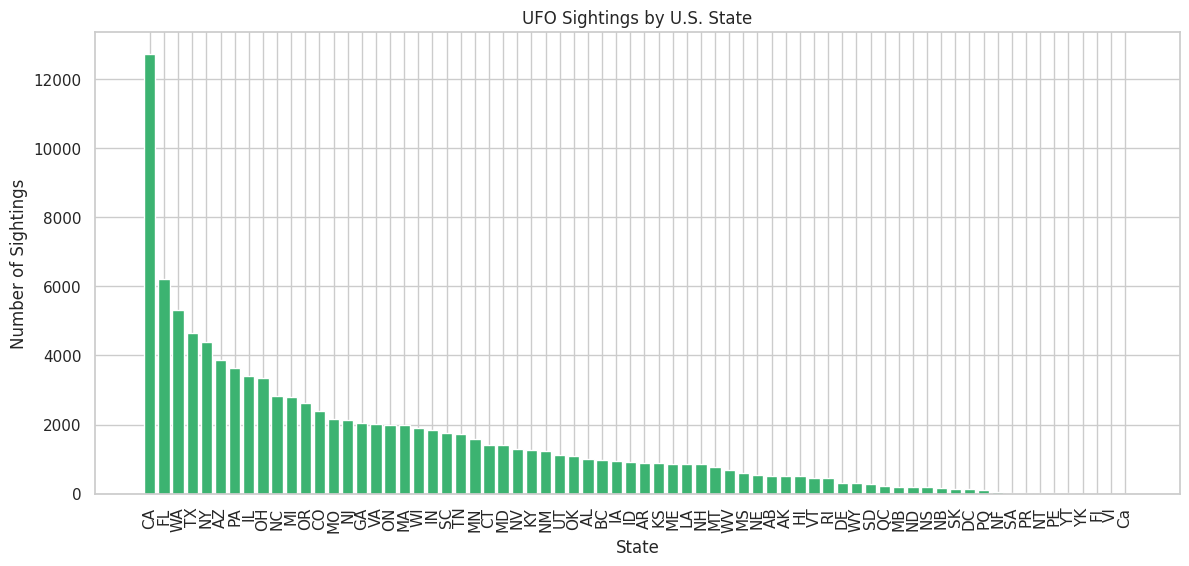

In [30]:
# Filtramos los registros que tienen un estado válido (excluyendo 'unknown')
us_sightings = df[df['state'] != 'unknown']
state_counts = us_sightings['state'].value_counts()
states = state_counts.index
sightings = state_counts.values

plt.figure(figsize=(14,6))
plt.bar(states, sightings, color='mediumseagreen')
plt.title('UFO Sightings by U.S. State')
plt.ylabel('Number of Sightings')
plt.xlabel('State')
plt.xticks(rotation=90)
plt.show()


##**ESTADO FINAL DEL DATASET DESPUÉS DEL PROCESAMIENTO**

Resultado del proceso de limpieza y preparación de los datos, con el objetivo de obtener un conjunto de datos consistente y adecuado para el desarrollo del modelo de aprendizaje automático.

Ahora tiene 29 columnas adicionales porque se pasaron variables de númericas a categóricas.

Asimismo, se evaluaron las categorías de `shape` para definir cuáles resultaban adecuadas para el objetivo de predicción.


In [31]:
# Información general del dataset
print("=" * 70)
print("INFORMACIÓN GENERAL DEL DATASET UFO")
print("=" * 70)

print(f"\nCantidad de filas: {df.shape[0]:,}")
print(f"Cantidad de columnas: {df.shape[1]:,}")
print(f"Tamaño del dataset: {df.memory_usage(deep=True).sum() / (1024**2):.2f} MB")

# Crear tabla resumen de las columnas
resumen = pd.DataFrame({
    'Tipo de dato': df.dtypes.astype(str),
    'Valores no nulos': df.notna().sum(),
    'Valores faltantes': df.isna().sum(),
    '% faltantes': (df.isna().mean() * 100).round(2),
    'Valores únicos': df.nunique()
})

# Mostrar tabla ordenada
display(resumen)

INFORMACIÓN GENERAL DEL DATASET UFO

Cantidad de filas: 111,753
Cantidad de columnas: 29
Tamaño del dataset: 144.45 MB


,Tipo de dato,Valores no nulos,Valores faltantes,% faltantes,Valores únicos
id,int64,111753,0,0.0,111753
occurred_date_time,object,111753,0,0.0,95077
city,object,111753,0,0.0,24139
state,object,111753,0,0.0,71
shape,object,111753,0,0.0,29
duration,object,111753,0,0.0,11257
summary,object,111753,0,0.0,111129
details_url,object,111753,0,0.0,111753
posted_date,object,111753,0,0.0,567
year,int64,111753,0,0.0,48


In [32]:
# Guarda el DataFrame en un archivo CSV (index=False evita guardar la columna numérica de índices)
df.to_csv('dataset_procesado.csv', index=False)

In [34]:
#from google.colab import files as colab_files
#colab_files.download('dataset_procesado.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>